# ESP32 ROI detector v3: outside-data pretraining experiment

This notebook runs a controlled, paired comparison of the existing **v2.1 ESP32-only detector** against the same detector after bird-box pretraining on CUB and high-confidence iNaturalist images.

## Experiment contract

* ESP32 ground truth comes from `Models/Manifests/bird_annotations.csv`.
* CUB contributes all 11,788 images; its eight slightly out-of-bounds boxes are clipped.
* iNaturalist contributes only images having exactly one predicted box in the file and that box scores at least 0.95. Multi-box images are dropped rather than treating uncertain birds as background.
* CUB and iNaturalist are **training only**. Validation and test contain ESP32 sessions only.
* ESP32 capture sessions are derived from timestamps using the repository's ten-minute grouping rule, then oversized sessions use the v2.1 block/buffer rule. The assignments and deterministic evaluation ROIs are saved and reused by both arms.
* Stage 1 pretrains on outside positive motion crops with ESP32-like degradation: resolution loss, JPEG quality 10–40, blur, noise, white-balance shifts, and occasional greyscale.
* Stage 2 compares:
  1. `esp32_only`: the v2.1 sampler and ImageNet initialization.
  2. `outside_pretrained`: Stage-1 weights and a hierarchical sampler with 75% ESP32 draws and 25% outside positive motion crops. Outside data never supplies negatives.
* Each arm selects its deployment threshold on the same ESP32 validation ROIs, maximizing crop recall subject to a 10% false-trigger limit. Test is evaluated once at that frozen threshold.
* Outside data is selected only if it improves test motion-ROI crop recall while remaining within the false-trigger limit.

The model architecture, target encoding, motion-ROI geometry, Pi crop metric, and int8 deployment format are inherited from v2.1. Run top to bottom. Set `QUICK_RUN = True` only for a pipeline smoke test.


## 1. Configuration


In [1]:
# ---- Manifests and images -----------------------------------------------------
ESP32_MANIFEST = r"C:\Users\Joe\Desktop\ESP_Classifier\esp32_Classifier\Models\Manifests\bird_annotations.csv"
INAT_MANIFEST = r"C:\Users\Joe\Desktop\ESP_Classifier\esp32_Classifier\Models\Manifests\bird_manifest.csv"
INAT_BOXES = r"C:\Users\Joe\Desktop\ESP_Classifier\esp32_Classifier\Models\Manifests\inaturalist_bird_boxes.csv"
CUB_MANIFEST = r"C:\Users\Joe\Desktop\ESP_Classifier\esp32_Classifier\Models\Manifests\cub_200_2011_image_manifest.csv"
ESP32_SIDECAR_ROOT = r"E:\Datasets\ESP32Cam_confirmed"
# Stored absolute paths in the manifests may reflect an older machine layout.
# Resolve by the stable relative path under the first existing matching root.
CUB_IMAGE_ROOTS = [
    r"E:\Datasets\CUB_200\CUB_200_2011\images",
    r"E:\Datasets\CUB_200_2011\CUB_200_2011\images",
]
INAT_IMAGE_ROOTS = [
    r"E:\Datasets\iNaturalist",
    r"E:\Datasets\Animals",
]
OUTPUT_ROOT = r"C:\Users\Joe\Desktop\ESP_Classifier\esp32_Classifier\Models\Multi_Object_Detector\runs"

# ---- Reproducibility and split policy ----------------------------------------
SEED = 1234
VAL_FRACTION = 0.15
TEST_FRACTION = 0.15
SESSION_GAP_MINUTES = 10
MAX_SESSION_IMAGES = 250
SESSION_BLOCK_MINUTES = 10
BLOCK_BUFFER_SECONDS = 60

# ---- Detector architecture: unchanged from v2.1 -----------------------------
INPUT_SIZE = 128
BACKBONE_ALPHA = 0.35
WEIGHTS = "imagenet"
FEATURE_LAYER = "block_13_expand_relu"
FEATURE_STRIDE = 16
NUM_ANCHORS = 3
HEAD_CHANNELS = 64
PAD_VALUE = 114

# ---- Motion ROI contract and v2.1 sampler ------------------------------------
ROI_EXPAND = 1.5
ROI_MIN_SIDE_FRACTION = 0.25
SAMPLE_MIX = {"bird_roi": 0.60, "random_roi": 0.30, "whole_frame": 0.10}
RANDOM_ROI_NO_BIRD_SHARE = 0.5
MOTION_SLACK_MAX = 1.0
MOTION_SHIFT_STD = 0.25
MOTION_UNION_PROB = 0.2
RANDOM_ROI_SIZE = (0.05, 0.8)
TRANSFER_ESP32_SHARE = 0.75

# ---- Outside-data filtering and degradation ----------------------------------
INAT_MIN_SCORE = 0.95
OUTSIDE_DOWNSCALE_RANGE = (0.30, 0.85)  # reduce a 128px ROI to 38–109px, then restore it
OUTSIDE_JPEG_QUALITY = (10, 40)
OUTSIDE_GREYSCALE_PROBABILITY = 0.12
OUTSIDE_BLUR_PROBABILITY = 0.65
OUTSIDE_NOISE_STD_RANGE = (1.0, 14.0)
OUTSIDE_WHITE_BALANCE_RANGE = (0.72, 1.28)

# ---- Target rules -------------------------------------------------------------
MIN_BOX_PX = 4
MIN_VISIBLE_FRACTION = 0.6
MIN_TARGET_PX = 6
NEIGHBOUR_POSITIVES = True
FOCAL_ALPHA = 0.25
FOCAL_GAMMA = 2.0
BOX_LOSS_WEIGHT = 2.0

# ---- Training -----------------------------------------------------------------
BATCH_SIZE = 64
STEPS_PER_EPOCH = 500
HEAD_EPOCHS = 6
FINE_TUNE_EPOCHS = 60
HEAD_LR = 2e-3
FINE_TUNE_LR = 3e-4
EARLY_STOP_PATIENCE = 12
PRETRAIN_HEAD_EPOCHS = 2
PRETRAIN_EPOCHS = 8
PRETRAIN_HEAD_LR = 2e-3
PRETRAIN_LR = 3e-4
PRETRAIN_STEPS_PER_EPOCH = None  # None means one draw per accepted outside image per epoch

# ---- Decode / evaluation ------------------------------------------------------
CANDIDATE_SCORE_THRESHOLD = 0.05
NMS_IOU = 0.45
MAX_DETECTIONS = 5
MAX_FALSE_TRIGGER_RATE = 0.10
THRESHOLD_MODES = ("bird_roi", "random_roi")
CROP_COVERAGE_MIN = 0.9
IOU_MATCH = 0.5
PI_CROP_CONTEXT = 0.25
PI_CROP_SIZE = 224
REPRESENTATIVE_SAMPLES = 400
TFLITE_EVAL_LIMIT = None
BOOTSTRAP_REPLICATES = 2000

QUICK_RUN = False
if QUICK_RUN:
    BATCH_SIZE = 8
    STEPS_PER_EPOCH = 2
    HEAD_EPOCHS = 1
    FINE_TUNE_EPOCHS = 1
    PRETRAIN_HEAD_EPOCHS = 1
    PRETRAIN_EPOCHS = 1
    PRETRAIN_STEPS_PER_EPOCH = 2
    EARLY_STOP_PATIENCE = 2
    REPRESENTATIVE_SAMPLES = 16
    TFLITE_EVAL_LIMIT = 96
    BOOTSTRAP_REPLICATES = 100

GRID = INPUT_SIZE // FEATURE_STRIDE
assert INPUT_SIZE % FEATURE_STRIDE == 0
assert abs(sum(SAMPLE_MIX.values()) - 1.0) < 1e-9
assert 0 < TRANSFER_ESP32_SHARE <= 1


## 2. Environment and shared helpers


In [2]:
import hashlib
import json
import math
import os
import platform
import random
import re
import time
from datetime import datetime, timezone
from pathlib import Path, PurePosixPath, PureWindowsPath, PureWindowsPath

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

keras = tf.keras

for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


def portable_path(raw_path):
    """Windows path <-> WSL /mnt/<drive> path, whichever this kernel needs."""
    raw = str(raw_path).strip()
    windows_path = PureWindowsPath(raw)
    if windows_path.drive:
        if os.name == "nt":
            return Path(raw)
        drive = windows_path.drive.rstrip(":").lower()
        return Path("/mnt") / drive / Path(*windows_path.parts[1:])
    mount = re.match(r"^/mnt/([A-Za-z])/(.*)$", raw.replace("\\", "/"))
    if mount and os.name == "nt":
        drive, rest = mount.groups()
        return Path(f"{drive.upper()}:/") / Path(*PurePosixPath(rest).parts)
    return Path(raw)


def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()


def parse_bool(series):
    return series.astype(str).str.strip().str.lower().isin(["true", "1", "1.0", "yes"])


def json_safe(value):
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(v) for v in value]
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, np.ndarray):
        return json_safe(value.tolist())
    if isinstance(value, np.generic):
        value = value.item()
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value


print("Python", platform.python_version(), "| TensorFlow", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

from collections import Counter, defaultdict
from dataclasses import dataclass
import copy
import shutil
import warnings

keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

ESP32_MANIFEST_PATH = portable_path(ESP32_MANIFEST)
INAT_MANIFEST_PATH = portable_path(INAT_MANIFEST)
INAT_BOXES_PATH = portable_path(INAT_BOXES)
CUB_MANIFEST_PATH = portable_path(CUB_MANIFEST)
ESP32_SIDECAR_ROOT_PATH = portable_path(ESP32_SIDECAR_ROOT)
CUB_IMAGE_ROOT_PATHS = [portable_path(root) for root in CUB_IMAGE_ROOTS]
INAT_IMAGE_ROOT_PATHS = [portable_path(root) for root in INAT_IMAGE_ROOTS]
OUTPUT_ROOT_PATH = portable_path(OUTPUT_ROOT)

for required_path in (ESP32_MANIFEST_PATH, INAT_MANIFEST_PATH, INAT_BOXES_PATH, CUB_MANIFEST_PATH):
    if not required_path.is_file():
        raise FileNotFoundError(required_path)

created_utc = datetime.now(timezone.utc)
RUN_NAME = f"esp32_roi_detector_v3_{INPUT_SIZE}_{created_utc:%Y%m%dT%H%M%SZ}"
RUN_DIR = OUTPUT_ROOT_PATH / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=False)
print("Run directory:", RUN_DIR)


def read_json_if_present(path):
    try:
        return json.loads(Path(path).read_text(encoding="utf-8"))
    except (FileNotFoundError, json.JSONDecodeError, OSError):
        return {}


def resolve_manifest_image(stored_path, relative_path, roots):
    """Resolve a manifest image without relying on a stale absolute path.

    The relative path is authoritative. Basename-only searching is deliberately
    avoided because UUID file names can occur in unrelated datasets.
    """
    direct = portable_path(stored_path) if isinstance(stored_path, str) and stored_path.strip() else None
    if direct is not None and direct.is_file():
        return direct
    relative = PurePosixPath(str(relative_path).replace("\\", "/"))
    for root in roots:
        candidate = root.joinpath(*relative.parts)
        if candidate.is_file():
            return candidate
    return None


def capture_timestamp(sample_id):
    match = re.match(r"capture_(\d{8}T\d{6})_(\d{6})Z", str(sample_id))
    return (pd.to_datetime("".join(match.groups()), format="%Y%m%dT%H%M%S%f")
            if match else pd.NaT)


def assign_timestamp_sessions(unique_rows, gap_minutes=SESSION_GAP_MINUTES):
    ordered = unique_rows[["sample_id"]].drop_duplicates().copy()
    ordered["time"] = ordered["sample_id"].map(capture_timestamp)
    ordered = ordered.sort_values(["time", "sample_id"], kind="stable")
    new_session = ordered["time"].diff() > pd.Timedelta(minutes=gap_minutes)
    ordered["group"] = "session_" + new_session.cumsum().astype(str).str.zfill(4)
    return ordered.set_index("sample_id")[["time", "group"]]


I0000 00:00:1794288105.651965    1556 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794288106.173884    1556 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794288108.079217    1556 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python 3.12.15 | TensorFlow 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Run directory: /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/Multi_Object_Detector/runs/esp32_roi_detector_v3_128_20261110T052149Z


## 3. Load ESP32 annotations, sidecar provenance, and session splits


In [3]:
esp = pd.read_csv(ESP32_MANIFEST_PATH, low_memory=False)
required = {"sample_id", "image_path", "relative_path", "width_px", "height_px", "review_state",
            "xmin", "ymin", "xmax", "ymax", "species_name"}
missing = required - set(esp.columns)
if missing:
    raise ValueError(f"ESP32 manifest is missing columns: {sorted(missing)}")
esp = esp[esp["review_state"].isin(["boxed", "no_bird"])].copy()
for column in ("xmin", "ymin", "xmax", "ymax", "width_px", "height_px"):
    esp[column] = pd.to_numeric(esp[column], errors="coerce")

sessions = assign_timestamp_sessions(esp)
sidecar_cache = {}
records = []
for sample_id, rows in esp.groupby("sample_id", sort=True):
    first = rows.iloc[0]
    width, height = int(first["width_px"]), int(first["height_px"])
    boxed = rows[rows["review_state"].eq("boxed") & rows["xmin"].notna()]
    xyxy = boxed[["xmin", "ymin", "xmax", "ymax"]].to_numpy(np.float32)
    if len(xyxy):
        xyxy[:, [0, 2]] = xyxy[:, [0, 2]].clip(0, width)
        xyxy[:, [1, 3]] = xyxy[:, [1, 3]].clip(0, height)
    size_ok = (((xyxy[:, 2] - xyxy[:, 0]) >= MIN_BOX_PX)
               & ((xyxy[:, 3] - xyxy[:, 1]) >= MIN_BOX_PX)) if len(xyxy) else np.zeros(0, bool)
    path = portable_path(first["image_path"])
    if not path.is_file():
        path = ESP32_SIDECAR_ROOT_PATH / PurePosixPath(str(first["relative_path"]).replace("\\", "/")).name
    sidecar = ESP32_SIDECAR_ROOT_PATH / f"{sample_id}.json"
    metadata = read_json_if_present(sidecar)
    camera = metadata.get("camera", {})
    capture = camera.get("observed", {}).get("capture", {})
    sensor = camera.get("sensor", {}).get("model", "unknown")
    camera_id = metadata.get("camera_id", "unknown")
    species = sorted({str(value).strip() for value in boxed["species_name"] if str(value).strip() and str(value) != "nan"})
    records.append({
        "sample_id": sample_id,
        "path": str(path) if path.is_file() else "",
        "width": width,
        "height": height,
        "source": str(sensor),
        "sensor": str(sensor),
        "camera_id": str(camera_id),
        "jpeg_quality": capture.get("jpeg_quality"),
        "group": str(sessions.loc[sample_id, "group"]),
        "time": sessions.loc[sample_id, "time"],
        "boxes": xyxy[size_ok],
        "ignore": xyxy[~size_ok],
        "has_bird": bool(len(xyxy)),
        "species": species,
        "dataset": "esp32",
    })

unresolved = [record for record in records if not record["path"]]
if unresolved:
    raise FileNotFoundError(f"{len(unresolved)} ESP32 images are missing, e.g. {[r['sample_id'] for r in unresolved[:5]]}")


def block_large_sessions(input_records):
    """Exact v2.1 oversized-session block rule, applied without mutating the input."""
    result = copy.deepcopy(input_records)
    sizes = pd.Series([r["group"] for r in result]).value_counts()
    kept, dropped = [], 0
    for record in result:
        if sizes[record["group"]] <= MAX_SESSION_IMAGES or pd.isna(record["time"]):
            kept.append(record)
            continue
        seconds = record["time"].hour * 3600 + record["time"].minute * 60 + record["time"].second
        block, offset = divmod(seconds, SESSION_BLOCK_MINUTES * 60)
        if offset < BLOCK_BUFFER_SECONDS / 2 or offset > SESSION_BLOCK_MINUTES * 60 - BLOCK_BUFFER_SECONDS / 2:
            dropped += 1
            continue
        record["group"] = f"{record['group']}/{record['time']:%Y%m%d}_block{block:04d}"
        kept.append(record)
    print(f"split {int((sizes > MAX_SESSION_IMAGES).sum())} large sessions; dropped {dropped} boundary frames")
    return kept


def assign_splits(input_records):
    """Whole capture groups go to one split, irrespective of reporting sensor."""
    rng = np.random.default_rng(SEED)
    split_of_group = {}
    groups = {}
    for record in input_records:
        groups[record["group"]] = groups.get(record["group"], 0) + 1
    names = sorted(groups)
    rng.shuffle(names)
    total = sum(groups.values())
    targets = {"test": TEST_FRACTION * total, "validation": VAL_FRACTION * total}
    counts = {"test": 0, "validation": 0}
    for name in names:
        size = groups[name]
        split = "train"
        for candidate in ("test", "validation"):
            room = targets[candidate] - counts[candidate]
            if size <= room * 1.25 or (counts[candidate] == 0 and size <= 2 * targets[candidate]):
                split = candidate
                break
        split_of_group[name] = split
        if split != "train":
            counts[split] += size
    for record in input_records:
        record["split"] = split_of_group[record["group"]]


records = block_large_sessions(records)
assign_splits(records)
train_records = [r for r in records if r["split"] == "train"]
val_records = [r for r in records if r["split"] == "validation"]
test_records = [r for r in records if r["split"] == "test"]

split_rows = [{
    "sample_id": r["sample_id"], "split": r["split"], "split_group": r["group"],
    "sensor": r["sensor"], "camera_id": r["camera_id"], "has_bird": r["has_bird"],
    "species": "|".join(r["species"]), "image_path": r["path"],
} for r in records]
split_frame = pd.DataFrame(split_rows).sort_values(["split", "sensor", "split_group", "sample_id"])
split_frame.to_csv(RUN_DIR / "esp32_split_assignments.csv", index=False)
display(pd.crosstab([split_frame["split"], split_frame["sensor"]], split_frame["has_bird"], margins=True))
display(split_frame.groupby("split")["split_group"].nunique().rename("sessions").to_frame())
if not train_records or not val_records or not test_records:
    raise RuntimeError("Session split produced an empty partition")


split 2 large sessions; dropped 315 boundary frames


has_bird           False  True   All
split      sensor                   
test       OV2640     34    49    83
           OV5640     90   382   472
train      OV2640    505   764  1269
           OV5640    221   871  1092
validation OV2640     51   205   256
           OV5640    135   125   260
All                 1036  2396  3432

,sessions
split,
test,8
train,38
validation,15


## 4. Load and audit CUB plus filtered iNaturalist


In [4]:
cub = pd.read_csv(CUB_MANIFEST_PATH, low_memory=False)
cub_records = []
for row in cub.itertuples(index=False):
    path = resolve_manifest_image(row.image_path, row.relative_path, CUB_IMAGE_ROOT_PATHS)
    box = np.array([row.bbox_x, row.bbox_y, row.bbox_right, row.bbox_bottom], np.float32)
    width, height = int(row.width_px), int(row.height_px)
    box[[0, 2]] = box[[0, 2]].clip(0, width)
    box[[1, 3]] = box[[1, 3]].clip(0, height)
    if path is None:
        raise FileNotFoundError(
            f"CUB image {row.image_id} was not found from stored path {row.image_path!r} "
            f"or relative path {row.relative_path!r} under {CUB_IMAGE_ROOT_PATHS}"
        )
    if box[2] <= box[0] or box[3] <= box[1]:
        raise ValueError(f"Invalid CUB box row {row.image_id}: {box.tolist()}")
    cub_records.append({
        "sample_id": f"cub:{row.image_id}", "path": str(path), "width": width, "height": height,
        "boxes": box[None], "ignore": np.empty((0, 4), np.float32), "has_bird": True,
        "source": "cub", "dataset": "cub", "species": [str(row.class_name_friendly)],
    })

inat_images = pd.read_csv(INAT_MANIFEST_PATH, low_memory=False)
inat_images["source_id"] = "inaturalist:" + inat_images["image_id"].astype(str)
inat_lookup = inat_images.set_index("source_id")
inat_boxes = pd.read_csv(INAT_BOXES_PATH)
inat_boxes["score"] = pd.to_numeric(inat_boxes["score"], errors="coerce")
box_counts = inat_boxes.groupby("source_id").size()
accepted_ids = box_counts[box_counts.eq(1)].index
accepted_boxes = inat_boxes[inat_boxes["source_id"].isin(accepted_ids) & inat_boxes["score"].ge(INAT_MIN_SCORE)].copy()
accepted_boxes = accepted_boxes[accepted_boxes["source_id"].isin(inat_lookup.index)]
inat_records = []
for row in accepted_boxes.itertuples(index=False):
    image = inat_lookup.loc[row.source_id]
    path = resolve_manifest_image(image.absolute_path, image.relative_path, INAT_IMAGE_ROOT_PATHS)
    width, height = int(image.width), int(image.height)
    box = np.array([row.x, row.y, row.x + row.w, row.y + row.h], np.float32)
    box[[0, 2]] = box[[0, 2]].clip(0, width)
    box[[1, 3]] = box[[1, 3]].clip(0, height)
    if path is None:
        raise FileNotFoundError(
            f"iNaturalist image {row.source_id} was not found from stored path {image.absolute_path!r} "
            f"or relative path {image.relative_path!r} under {INAT_IMAGE_ROOT_PATHS}"
        )
    if box[2] <= box[0] or box[3] <= box[1]:
        raise ValueError(f"Invalid iNaturalist box row {row.source_id}: {box.tolist()}")
    inat_records.append({
        "sample_id": row.source_id, "path": str(path), "width": width, "height": height,
        "boxes": box[None], "ignore": np.empty((0, 4), np.float32), "has_bird": True,
        "source": "inaturalist", "dataset": "inaturalist", "species": [str(image.common_name)],
    })

outside_records = cub_records + inat_records
audit = {
    "manifests": {
        "esp32": {"path": str(ESP32_MANIFEST_PATH), "sha256": sha256_file(ESP32_MANIFEST_PATH)},
        "cub": {"path": str(CUB_MANIFEST_PATH), "sha256": sha256_file(CUB_MANIFEST_PATH)},
        "inaturalist_images": {"path": str(INAT_MANIFEST_PATH), "sha256": sha256_file(INAT_MANIFEST_PATH)},
        "inaturalist_boxes": {"path": str(INAT_BOXES_PATH), "sha256": sha256_file(INAT_BOXES_PATH)},
    },
    "esp32": {"before_block_buffers": int(esp["sample_id"].nunique()), "used": len(records),
                "train": len(train_records), "validation": len(val_records), "test": len(test_records)},
    "cub": {"manifest_images": len(cub), "accepted": len(cub_records)},
    "inaturalist": {"boxed_images": int(inat_boxes["source_id"].nunique()),
                     "single_box_images": int(box_counts.eq(1).sum()),
                     "single_box_score_gte_threshold": len(inat_records),
                     "threshold": INAT_MIN_SCORE,
                     "multi_box_images_dropped": int(box_counts.gt(1).sum())},
    "outside_total": len(outside_records),
}
(RUN_DIR / "data_audit.json").write_text(json.dumps(json_safe(audit), indent=2), encoding="utf-8")
display(pd.DataFrame({
    "images": [len(train_records), len(val_records), len(test_records), len(cub_records), len(inat_records)],
}, index=["ESP32 train", "ESP32 validation", "ESP32 test", "CUB pretrain", "iNaturalist pretrain"]))
print(json.dumps(json_safe(audit["inaturalist"]), indent=2))
assert len(cub_records) == 11788
assert len(inat_records) == 56369, "Filtering no longer matches the audited 56,369-image set"


,images
ESP32 train,2361
ESP32 validation,516
ESP32 test,555
CUB pretrain,11788
iNaturalist pretrain,56369


{
  "boxed_images": 66672,
  "single_box_images": 59127,
  "single_box_score_gte_threshold": 56369,
  "threshold": 0.95,
  "multi_box_images_dropped": 7545
}


## 5. Geometry contract inherited from v2.1


In [5]:
def square_roi(motion_box, frame_w, frame_h):
    """Motion box (l, t, r, b in frame pixels) -> square integer ROI (may extend past the frame)."""
    left, top, right, bottom = [float(v) for v in motion_box]
    cx, cy = (left + right) / 2.0, (top + bottom) / 2.0
    side = max(right - left, bottom - top) * ROI_EXPAND
    side = max(side, ROI_MIN_SIDE_FRACTION * min(frame_w, frame_h))
    side = min(side, max(frame_w, frame_h))
    side = max(1, int(round(side)))
    x0 = int(round(cx - side / 2.0))
    y0 = int(round(cy - side / 2.0))
    # Prefer real pixels over padding: slide inside the frame when it fits, else centre it.
    x0 = min(max(x0, 0), frame_w - side) if side <= frame_w else (frame_w - side) // 2
    y0 = min(max(y0, 0), frame_h - side) if side <= frame_h else (frame_h - side) // 2
    return (x0, y0, x0 + side, y0 + side)


def reference_sample(image, region, out_w, out_h, pad_value=PAD_VALUE):
    """Bilinear resample of region (l, t, r, b; floats allowed) to out_h x out_w. image: HxWx3 uint8."""
    height, width = image.shape[:2]
    left, top, right, bottom = [float(v) for v in region]
    xs = left + (np.arange(out_w) + 0.5) * (right - left) / out_w - 0.5
    ys = top + (np.arange(out_h) + 0.5) * (bottom - top) / out_h - 0.5
    gx, gy = np.meshgrid(xs, ys)
    inside = (gx >= 0) & (gx <= width - 1) & (gy >= 0) & (gy <= height - 1)
    x0 = np.clip(np.floor(gx), 0, width - 1).astype(int)
    y0 = np.clip(np.floor(gy), 0, height - 1).astype(int)
    x1 = np.clip(x0 + 1, 0, width - 1)
    y1 = np.clip(y0 + 1, 0, height - 1)
    fx = (gx - np.floor(gx))[..., None]
    fy = (gy - np.floor(gy))[..., None]
    img = image.astype(np.float32)
    top_row = img[y0, x0] * (1 - fx) + img[y0, x1] * fx
    bottom_row = img[y1, x0] * (1 - fx) + img[y1, x1] * fx
    out = top_row * (1 - fy) + bottom_row * fy
    out[~inside] = pad_value
    return out


def roi_to_crop_box(roi, frame_w, frame_h, out_size=INPUT_SIZE):
    """Normalized [y1, x1, y2, x2] so tf.image.crop_and_resize == reference_sample."""
    left, top, right, bottom = [float(v) for v in roi]
    sx, sy = (right - left) / out_size, (bottom - top) / out_size
    x_first, x_last = left + 0.5 * sx - 0.5, left + (out_size - 0.5) * sx - 0.5
    y_first, y_last = top + 0.5 * sy - 0.5, top + (out_size - 0.5) * sy - 0.5
    return np.array([y_first / max(frame_h - 1, 1), x_first / max(frame_w - 1, 1),
                     y_last / max(frame_h - 1, 1), x_last / max(frame_w - 1, 1)], np.float32)


def roi_box_to_frame(box_norm, roi):
    """Detector box (normalized to the ROI) -> frame pixels."""
    left, top, right, bottom = roi
    side = right - left
    x1, y1, x2, y2 = box_norm
    return np.array([left + x1 * side, top + y1 * side, left + x2 * side, top + y2 * side], np.float32)


def pi_crop_region(box_px, frame_w, frame_h, context=PI_CROP_CONTEXT):
    """Expand a frame-pixel box by `context` of its size on every edge, clip, round outward."""
    x1, y1, x2, y2 = [float(v) for v in box_px]
    w, h = x2 - x1, y2 - y1
    left = int(math.floor(max(0.0, x1 - context * w)))
    top = int(math.floor(max(0.0, y1 - context * h)))
    right = int(math.ceil(min(float(frame_w), x2 + context * w)))
    bottom = int(math.ceil(min(float(frame_h), y2 + context * h)))
    return (left, top, max(right, left + 1), max(bottom, top + 1))


def make_pi_crop(image, box_px, out_size=PI_CROP_SIZE, context=PI_CROP_CONTEXT, pad_value=PAD_VALUE):
    """What the ESP32 sends: context crop, aspect-preserving resize, centred on a pad canvas."""
    height, width = image.shape[:2]
    left, top, right, bottom = pi_crop_region(box_px, width, height, context)
    crop_w, crop_h = right - left, bottom - top
    scale = min(out_size / crop_w, out_size / crop_h)
    new_w = max(1, min(out_size, int(round(crop_w * scale))))
    new_h = max(1, min(out_size, int(round(crop_h * scale))))
    off_x, off_y = (out_size - new_w) // 2, (out_size - new_h) // 2
    canvas = np.full((out_size, out_size, 3), pad_value, np.float32)
    canvas[off_y:off_y + new_h, off_x:off_x + new_w] = reference_sample(image, (left, top, right, bottom), new_w, new_h)
    meta = {"crop_px": [left, top, right, bottom], "scale": scale, "offset": [off_x, off_y], "size": [new_w, new_h]}
    return np.clip(np.rint(canvas), 0, 255).astype(np.uint8), meta


def decode_rgb(path):
    return tf.io.decode_jpeg(tf.io.read_file(path), channels=3).numpy()


# --- verify TF sampling == reference, including regions that run off the frame ---
check = next(r for r in train_records if r["has_bird"]) if any(r["has_bird"] for r in train_records) else train_records[0]
frame = decode_rgb(check["path"])
H, W = frame.shape[:2]
worst = 0.0
for roi in [square_roi((0, 0, W, H), W, H), square_roi((W * 0.4, H * 0.4, W * 0.5, H * 0.55), W, H),
            (-W // 4, -H // 4, -W // 4 + int(W * 0.7), -H // 4 + int(W * 0.7)), (W // 3, H // 5, W // 3 + 37, H // 5 + 37)]:
    ref = reference_sample(frame, roi, INPUT_SIZE, INPUT_SIZE)
    tf_out = tf.image.crop_and_resize(tf.cast(frame, tf.float32)[None], roi_to_crop_box(roi, W, H)[None], [0],
                                      [INPUT_SIZE, INPUT_SIZE], method="bilinear", extrapolation_value=PAD_VALUE)[0].numpy()
    worst = max(worst, float(np.abs(ref - tf_out).max()))
print(f"max |reference - tf.crop_and_resize| = {worst:.4f} (0-255 scale)")
assert worst < 0.6, "TF pipeline does not match the reference sampler"


I0000 00:00:1794288924.190456    1556 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3582 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


max |reference - tf.crop_and_resize| = 0.0066 (0-255 scale)


## 6. Target encoding, fixed evaluation ROIs, and hierarchical samplers


In [6]:
def to_roi_norm(boxes_px, roi):
    left, top, right, _ = roi
    side = float(right - left)
    out = (boxes_px - np.array([left, top, left, top], np.float32)) / side
    return out.astype(np.float32)


def roi_targets_from_record(record, roi):
    """Split the record's boxes into positives / ignore areas for this ROI (normalized xyxy)."""
    positives, ignores = [], []
    side = roi[2] - roi[0]
    for box in to_roi_norm(record["boxes"], roi) if len(record["boxes"]) else []:
        area = max(1e-9, (box[2] - box[0]) * (box[3] - box[1]))
        clipped = np.clip(box, 0.0, 1.0)
        visible = max(0.0, clipped[2] - clipped[0]) * max(0.0, clipped[3] - clipped[1])
        if visible <= 0:
            continue
        small = min(clipped[2] - clipped[0], clipped[3] - clipped[1]) * INPUT_SIZE < MIN_TARGET_PX
        (ignores if (visible / area < MIN_VISIBLE_FRACTION or small) else positives).append(clipped)
    for box in to_roi_norm(record["ignore"], roi) if len(record["ignore"]) else []:
        clipped = np.clip(box, 0.0, 1.0)
        if clipped[2] > clipped[0] and clipped[3] > clipped[1]:
            ignores.append(clipped)
    as_array = lambda items: np.asarray(items, np.float32).reshape(-1, 4)
    return as_array(positives), as_array(ignores)


def simulated_motion_box(record, rng, mode):
    W, H = record["width"], record["height"]
    if mode == "whole_frame":
        return (0, 0, W, H)
    if mode == "bird_roi" and len(record["boxes"]):
        boxes = record["boxes"]
        if len(boxes) > 1 and rng.random() < MOTION_UNION_PROB:
            x1, y1 = boxes[:, 0].min(), boxes[:, 1].min()
            x2, y2 = boxes[:, 2].max(), boxes[:, 3].max()
        else:
            x1, y1, x2, y2 = boxes[rng.integers(len(boxes))]
        bw, bh = x2 - x1, y2 - y1
        size = max(bw, bh)
        x1 -= rng.uniform(0, MOTION_SLACK_MAX) * bw
        x2 += rng.uniform(0, MOTION_SLACK_MAX) * bw
        y1 -= rng.uniform(0, MOTION_SLACK_MAX) * bh
        y2 += rng.uniform(0, MOTION_SLACK_MAX) * bh
        dx, dy = rng.normal(0, MOTION_SHIFT_STD, 2) * size
        return (x1 + dx, y1 + dy, x2 + dx, y2 + dy)
    lo, hi = RANDOM_ROI_SIZE
    size = math.exp(rng.uniform(math.log(lo), math.log(hi))) * min(W, H)
    aspect = math.exp(rng.uniform(-0.5, 0.5))
    bw, bh = size * aspect, size / aspect
    cx, cy = rng.uniform(0, W), rng.uniform(0, H)
    return (cx - bw / 2, cy - bh / 2, cx + bw / 2, cy + bh / 2)


def encode_targets(positives, ignores, anchors):
    """-> (G, G, A, 6): [tx_target, ty_target, tw, th, objectness, ignore]."""
    target = np.zeros((GRID, GRID, NUM_ANCHORS, 6), np.float32)
    centres = (np.arange(GRID) + 0.5) / GRID
    for box in np.concatenate([ignores, positives]):
        ix = (centres >= box[0]) & (centres <= box[2])
        iy = (centres >= box[1]) & (centres <= box[3])
        target[iy[:, None] & ix[None, :], :, 5] = 1.0
    order = np.argsort(-(positives[:, 2] - positives[:, 0]) * (positives[:, 3] - positives[:, 1]))
    for box in positives[order]:
        cx, cy = (box[0] + box[2]) / 2, (box[1] + box[3]) / 2
        w, h = max(box[2] - box[0], 1e-4), max(box[3] - box[1], 1e-4)
        gx, gy = min(int(cx * GRID), GRID - 1), min(int(cy * GRID), GRID - 1)
        cells = [(gx, gy)]
        if NEIGHBOUR_POSITIVES:
            # The decode range (-1, 2) lets a neighbour predict this centre; using the two nearest
            # neighbours triples positives and stabilises boxes for birds near cell edges.
            fx, fy = cx * GRID - gx, cy * GRID - gy
            nx, ny = (gx - 1 if fx < 0.5 else gx + 1), (gy - 1 if fy < 0.5 else gy + 1)
            cells += [(x, y) for x, y in ((nx, gy), (gx, ny)) if 0 <= x < GRID and 0 <= y < GRID]
        inter = np.minimum(w, anchors[:, 0]) * np.minimum(h, anchors[:, 1])
        ious = inter / (w * h + anchors[:, 0] * anchors[:, 1] - inter)
        for cell_x, cell_y in cells:
            for a in np.argsort(-ious):
                if target[cell_y, cell_x, a, 4] == 0:
                    target[cell_y, cell_x, a] = [(cx * GRID - cell_x + 1) / 3, (cy * GRID - cell_y + 1) / 3,
                                                 math.log(w / anchors[a, 0]), math.log(h / anchors[a, 1]), 1.0, 0.0]
                    break
    return target




TRAIN_BIRD = [r for r in train_records if len(r["boxes"])]
TRAIN_NEG = [r for r in train_records if not r["has_bird"]]
MODES = list(SAMPLE_MIX)
MODE_P = np.array([SAMPLE_MIX[mode] for mode in MODES], np.float64)


def finish_draw(record, roi, mode, rng, sample_pool):
    positives, ignores = roi_targets_from_record(record, roi)
    flip = bool(rng.random() < 0.5)
    if flip:
        positives = positives[:, [2, 1, 0, 3]] * [-1, 1, -1, 1] + [1, 0, 1, 0]
        ignores = ignores[:, [2, 1, 0, 3]] * [-1, 1, -1, 1] + [1, 0, 1, 0]
    return {
        "record": record, "roi": roi, "mode": mode, "flip": flip,
        "positives": positives.astype(np.float32), "ignores": ignores.astype(np.float32),
        "sample_pool": sample_pool,
    }


def draw_esp32(rng):
    """The existing v2.1 sampler, unchanged apart from provenance logging."""
    mode = MODES[rng.choice(len(MODES), p=MODE_P)]
    if mode == "bird_roi" and TRAIN_BIRD:
        record = TRAIN_BIRD[rng.integers(len(TRAIN_BIRD))]
    elif mode == "random_roi" and TRAIN_NEG and rng.random() < RANDOM_ROI_NO_BIRD_SHARE:
        record = TRAIN_NEG[rng.integers(len(TRAIN_NEG))]
    else:
        record = train_records[rng.integers(len(train_records))]
    roi = square_roi(simulated_motion_box(record, rng, mode), record["width"], record["height"])
    return finish_draw(record, roi, mode, rng, "esp32")


def draw_outside(rng, record=None):
    """Outside data supplies positive simulated-motion crops only."""
    if record is None:
        record = outside_records[rng.integers(len(outside_records))]
    mode = "bird_roi"
    roi = square_roi(simulated_motion_box(record, rng, mode), record["width"], record["height"])
    return finish_draw(record, roi, mode, rng, record["dataset"])


def draw_transfer(rng):
    return draw_esp32(rng) if rng.random() < TRANSFER_ESP32_SHARE else draw_outside(rng)


def fit_anchors(samples=6000, iterations=60):
    """Fit shared anchors from ESP32 training draws so both arms use the same contract."""
    rng = np.random.default_rng(SEED + 7)
    wh = []
    while len(wh) < samples:
        draw = draw_esp32(rng)
        positives = draw["positives"]
        wh.extend((positives[:, 2:] - positives[:, :2]).tolist())
    wh = np.asarray(wh[:samples], np.float32)
    centres = wh[rng.choice(len(wh), NUM_ANCHORS, replace=False)]
    for _ in range(iterations):
        inter = np.minimum(wh[:, None, 0], centres[None, :, 0]) * np.minimum(wh[:, None, 1], centres[None, :, 1])
        iou = inter / (wh[:, None].prod(-1) + centres[None].prod(-1) - inter)
        assign = iou.argmax(1)
        centres = np.array([np.median(wh[assign == k], 0) if np.any(assign == k) else centres[k]
                            for k in range(NUM_ANCHORS)])
    return centres[np.argsort(centres.prod(1))].astype(np.float32)


ANCHORS = fit_anchors(samples=1500 if QUICK_RUN else 6000)
print("shared anchors (normalized w, h):\n", np.round(ANCHORS, 4))
(RUN_DIR / "anchors.json").write_text(json.dumps(ANCHORS.tolist()), encoding="utf-8")


def fixed_roi_set(subset, seed):
    """One deterministic bird ROI if applicable, one random ROI, and one whole frame per image."""
    rng = np.random.default_rng(seed)
    items = []
    for record in subset:
        modes = (["bird_roi"] if len(record["boxes"]) else []) + ["random_roi", "whole_frame"]
        for mode in modes:
            roi = square_roi(simulated_motion_box(record, rng, mode), record["width"], record["height"])
            positives, ignores = roi_targets_from_record(record, roi)
            items.append({"record": record, "roi": roi, "mode": mode,
                          "positives": positives, "ignores": ignores})
    return items


val_rois = fixed_roi_set(val_records, SEED + 11)
test_rois = fixed_roi_set(test_records, SEED + 13)


def roi_definition_rows(items, split):
    rows = []
    for index, item in enumerate(items):
        record = item["record"]
        rows.append({
            "roi_index": index, "split": split, "sample_id": record["sample_id"],
            "split_group": record["group"], "sensor": record["sensor"], "camera_id": record["camera_id"],
            "mode": item["mode"], "roi_x": item["roi"][0], "roi_y": item["roi"][1],
            "roi_side": item["roi"][2], "positive_boxes": len(item["positives"]),
            "ignore_boxes": len(item["ignores"]), "species": "|".join(record["species"]),
        })
    return rows


pd.DataFrame(roi_definition_rows(val_rois, "validation") + roi_definition_rows(test_rois, "test")).to_csv(
    RUN_DIR / "fixed_evaluation_rois.csv", index=False)
display(pd.DataFrame({
    "validation": [len(val_rois), sum(len(x["positives"]) > 0 for x in val_rois),
                   sum(len(x["positives"]) == 0 and len(x["ignores"]) == 0 for x in val_rois)],
    "test": [len(test_rois), sum(len(x["positives"]) > 0 for x in test_rois),
             sum(len(x["positives"]) == 0 and len(x["ignores"]) == 0 for x in test_rois)],
}, index=["ROIs", "with bird", "negative"]))

# Deterministic sampler audit: this does not consume the generators used for training.
audit_rng = np.random.default_rng(SEED + 101)
control_audit = Counter((d["sample_pool"], d["mode"]) for d in (draw_esp32(audit_rng) for _ in range(10000)))
transfer_audit = Counter((d["sample_pool"], d["mode"]) for d in (draw_transfer(audit_rng) for _ in range(10000)))
sampler_audit = {"esp32_only": {f"{a}/{b}": n for (a, b), n in control_audit.items()},
                 "outside_pretrained": {f"{a}/{b}": n for (a, b), n in transfer_audit.items()}}
(RUN_DIR / "sampler_audit.json").write_text(json.dumps(sampler_audit, indent=2), encoding="utf-8")
print(json.dumps(sampler_audit, indent=2))


shared anchors (normalized w, h):
 [[0.0919 0.0917]
 [0.2044 0.2336]
 [0.3106 0.3106]]


,validation,test
ROIs,1362,1541
with bird,756,996
negative,545,489


{
  "esp32_only": {
    "esp32/bird_roi": 6047,
    "esp32/random_roi": 2962,
    "esp32/whole_frame": 991
  },
  "outside_pretrained": {
    "esp32/bird_roi": 4505,
    "inaturalist/bird_roi": 2123,
    "esp32/random_roi": 2200,
    "esp32/whole_frame": 729,
    "cub/bird_roi": 443
  }
}


## 7. TensorFlow pipelines and ESP32-like outside degradation


I0000 00:00:1794288927.869209    1556 cuda_dnn.cc:461] Loaded cuDNN version 92700


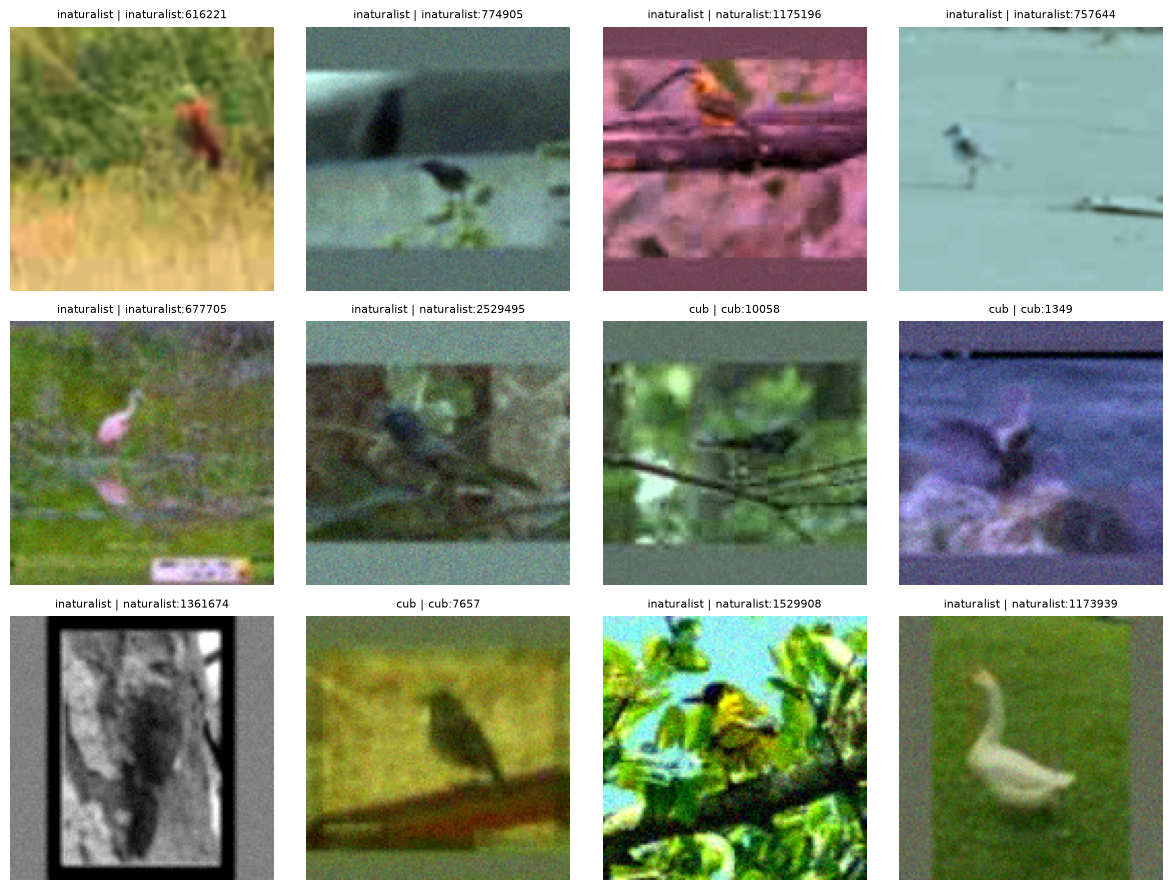

In [7]:
AUTOTUNE = tf.data.AUTOTUNE


def load_roi_tensor(path, crop_box, flip):
    image = tf.cast(tf.io.decode_jpeg(tf.io.read_file(path), channels=3), tf.float32)
    out = tf.image.crop_and_resize(image[None], crop_box[None], [0], [INPUT_SIZE, INPUT_SIZE],
                                   method="bilinear", extrapolation_value=float(PAD_VALUE))[0]
    out = tf.cond(flip, lambda: tf.image.flip_left_right(out), lambda: out)
    return tf.ensure_shape(out, (INPUT_SIZE, INPUT_SIZE, 3))


def random_brightness_arithmetic(image, max_delta):
    """Deterministic-GPU-safe equivalent of random brightness."""
    delta = tf.random.uniform([], -max_delta, max_delta, dtype=image.dtype)
    return image + delta


def random_contrast_arithmetic(image, lower, upper):
    """Scale per-channel deviations from the spatial mean without AdjustContrastv2."""
    factor = tf.random.uniform([], lower, upper, dtype=image.dtype)
    mean = tf.reduce_mean(image, axis=(0, 1), keepdims=True)
    return (image - mean) * factor + mean


def random_saturation_arithmetic(image, lower, upper):
    """Interpolate RGB chroma around luminance without AdjustSaturation."""
    factor = tf.random.uniform([], lower, upper, dtype=image.dtype)
    grey = tf.image.grayscale_to_rgb(tf.image.rgb_to_grayscale(image))
    return grey + factor * (image - grey)


def standard_color_augment(image):
    image = random_brightness_arithmetic(image, 20.0)
    image = random_contrast_arithmetic(image, 0.8, 1.2)
    image = random_saturation_arithmetic(image, 0.7, 1.3)
    grey = tf.image.grayscale_to_rgb(tf.image.rgb_to_grayscale(image))
    image = tf.where(tf.random.uniform([]) < 0.1, grey, image)
    return tf.clip_by_value(image, 0.0, 255.0)


def outside_degrade(image):
    """Destroy clean-photo cues before the final 128x128 detector input."""
    scale = tf.random.uniform([], OUTSIDE_DOWNSCALE_RANGE[0], OUTSIDE_DOWNSCALE_RANGE[1])
    side = tf.maximum(24, tf.cast(tf.round(INPUT_SIZE * scale), tf.int32))
    image = tf.image.resize(image, [side, side], method="area", antialias=True)
    image = tf.image.resize(image, [INPUT_SIZE, INPUT_SIZE], method="bilinear", antialias=False)
    image = tf.cast(tf.clip_by_value(tf.round(image), 0, 255), tf.uint8)
    image = tf.image.random_jpeg_quality(image, OUTSIDE_JPEG_QUALITY[0], OUTSIDE_JPEG_QUALITY[1])
    image = tf.cast(image, tf.float32)
    image = tf.cond(tf.random.uniform([]) < OUTSIDE_BLUR_PROBABILITY,
                    lambda: tf.nn.avg_pool2d(image[None], ksize=3, strides=1, padding="SAME")[0],
                    lambda: image)
    gains = tf.random.uniform([1, 1, 3], OUTSIDE_WHITE_BALANCE_RANGE[0], OUTSIDE_WHITE_BALANCE_RANGE[1])
    gains = gains / tf.reduce_mean(gains)
    image *= gains
    noise_std = tf.random.uniform([], OUTSIDE_NOISE_STD_RANGE[0], OUTSIDE_NOISE_STD_RANGE[1])
    image += tf.random.normal(tf.shape(image), stddev=noise_std)
    image = random_brightness_arithmetic(image, 24.0)
    image = random_contrast_arithmetic(image, 0.70, 1.30)
    image = random_saturation_arithmetic(image, 0.55, 1.35)
    grey = tf.image.grayscale_to_rgb(tf.image.rgb_to_grayscale(image))
    image = tf.where(tf.random.uniform([]) < OUTSIDE_GREYSCALE_PROBABILITY, grey, image)
    return tf.ensure_shape(tf.clip_by_value(image, 0.0, 255.0), (INPUT_SIZE, INPUT_SIZE, 3))


def map_training_example(path, crop_box, flip, target, outside):
    image = load_roi_tensor(path, crop_box, flip)
    image = tf.cond(outside, lambda: outside_degrade(image), lambda: standard_color_augment(image))
    return image, target


signature = (
    tf.TensorSpec((), tf.string), tf.TensorSpec((4,), tf.float32), tf.TensorSpec((), tf.bool),
    tf.TensorSpec((GRID, GRID, NUM_ANCHORS, 6), tf.float32), tf.TensorSpec((), tf.bool),
)


def yielded(draw):
    record = draw["record"]
    return (record["path"], roi_to_crop_box(draw["roi"], record["width"], record["height"]), draw["flip"],
            encode_targets(draw["positives"], draw["ignores"], ANCHORS), draw["sample_pool"] != "esp32")


def random_generator(draw_function, seed):
    rng = np.random.default_rng(seed)
    while True:
        yield yielded(draw_function(rng))


def pretrain_generator(seed):
    """Cycle shuffled permutations so every accepted outside image is visited."""
    rng = np.random.default_rng(seed)
    while True:
        for index in rng.permutation(len(outside_records)):
            yield yielded(draw_outside(rng, outside_records[index]))


def training_dataset(generator_function):
    return (tf.data.Dataset.from_generator(generator_function, output_signature=signature)
            .map(map_training_example, num_parallel_calls=AUTOTUNE)
            .batch(BATCH_SIZE, drop_remainder=True).prefetch(AUTOTUNE))


pretrain_ds = training_dataset(lambda: pretrain_generator(SEED + 201))
control_ds = training_dataset(lambda: random_generator(draw_esp32, SEED + 301))
transfer_ds = training_dataset(lambda: random_generator(draw_transfer, SEED + 401))


def eval_dataset(items):
    paths = [item["record"]["path"] for item in items]
    boxes = np.stack([roi_to_crop_box(item["roi"], item["record"]["width"], item["record"]["height"])
                      for item in items])
    targets = np.stack([encode_targets(item["positives"], item["ignores"], ANCHORS) for item in items])
    ds = tf.data.Dataset.from_tensor_slices((paths, boxes, targets))
    ds = ds.map(lambda path, box, target: (load_roi_tensor(path, box, tf.constant(False)), target),
                num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)


val_ds = eval_dataset(val_rois)

# Preview clean and degraded outside crops before expensive training.
preview_rng = np.random.default_rng(SEED + 99)
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax in axes.flat:
    draw = draw_outside(preview_rng)
    record = draw["record"]
    clean = load_roi_tensor(record["path"], roi_to_crop_box(draw["roi"], record["width"], record["height"]),
                            tf.constant(draw["flip"]))
    ax.imshow(outside_degrade(clean).numpy().astype(np.uint8))
    ax.set_title(f"{record['dataset']} | {record['sample_id'][-18:]}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.savefig(RUN_DIR / "outside_augmentation_preview.png", dpi=140, bbox_inches="tight")


## 8. Model and loss: unchanged from v2.1


In [8]:
def build_models():
    inputs = keras.Input((INPUT_SIZE, INPUT_SIZE, 3), name="image")
    x = keras.layers.Rescaling(1.0 / 127.5, offset=-1.0, name="scale_to_mobilenet")(inputs)
    backbone = keras.applications.MobileNetV2(
        input_shape=(INPUT_SIZE, INPUT_SIZE, 3), alpha=BACKBONE_ALPHA, include_top=False, weights=WEIGHTS)
    features = keras.Model(backbone.input, backbone.get_layer(FEATURE_LAYER).output, name="backbone")
    if WEIGHTS is None:
        # MobileNetV2's BN momentum (0.999) assumes pretrained statistics; from scratch
        # the moving averages would lag thousands of steps behind and break validation.
        for layer in features.layers:
            if isinstance(layer, keras.layers.BatchNormalization):
                layer.momentum = 0.9
    f = features(x)
    h = keras.layers.SeparableConv2D(HEAD_CHANNELS, 3, padding="same", use_bias=False, name="head_sep")(f)
    h = keras.layers.BatchNormalization(name="head_bn")(h)
    h = keras.layers.ReLU(6.0, name="head_relu")(h)
    box = keras.layers.Conv2D(NUM_ANCHORS * 4, 1, name="box")(h)
    score = keras.layers.Conv2D(NUM_ANCHORS, 1, name="score",
                                bias_initializer=keras.initializers.Constant(-4.6))(h)  # prior ~1%
    deploy = keras.Model(inputs, [box, score], name="esp32_bird_detector")
    packed = keras.layers.Concatenate(axis=-1, name="packed")([
        keras.layers.Reshape((GRID, GRID, NUM_ANCHORS, 4))(box),
        keras.layers.Reshape((GRID, GRID, NUM_ANCHORS, 1))(score),
    ])
    train = keras.Model(inputs, packed, name="esp32_bird_detector_train")
    return deploy, train, features


def detector_loss(y_true, y_pred):
    obj, ignore = y_true[..., 4], y_true[..., 5]
    logits = y_pred[..., 4]
    prob = tf.sigmoid(logits)
    bce = tf.nn.sigmoid_cross_entropy_with_logits(labels=obj, logits=logits)
    p_t = obj * prob + (1 - obj) * (1 - prob)
    alpha_t = obj * FOCAL_ALPHA + (1 - obj) * (1 - FOCAL_ALPHA)
    focal = alpha_t * tf.pow(1 - p_t, FOCAL_GAMMA) * bce
    score_mask = obj + (1 - obj) * (1 - ignore)
    n_pos = tf.maximum(tf.reduce_sum(obj), 1.0)
    score_loss = tf.reduce_sum(focal * score_mask) / n_pos
    t_xy = y_true[..., 0:2]
    xy_entropy = -(t_xy * tf.math.log(tf.clip_by_value(t_xy, 1e-6, 1.0))
                   + (1 - t_xy) * tf.math.log(tf.clip_by_value(1 - t_xy, 1e-6, 1.0)))
    # minus the target entropy: same gradients, but the loss reaches 0 at a perfect box
    xy = tf.reduce_sum(obj[..., None] * (tf.nn.sigmoid_cross_entropy_with_logits(labels=t_xy, logits=y_pred[..., 0:2]) - xy_entropy), -1)
    err = tf.abs(y_true[..., 2:4] - y_pred[..., 2:4])
    wh = tf.reduce_sum(tf.where(err < 1.0, 0.5 * tf.square(err), err - 0.5), -1)  # Huber, delta 1
    box_loss = tf.reduce_sum(obj * (xy + wh)) / n_pos
    return score_loss + BOX_LOSS_WEIGHT * box_loss




def count_macs(model):
    macs = 0
    stack = list(model.layers)
    while stack:
        layer = stack.pop()
        if isinstance(layer, keras.Model):
            stack.extend(layer.layers)
            continue
        if not hasattr(layer, "kernel_size"):
            continue
        out_h, out_w = layer.output.shape[1], layer.output.shape[2]
        k = int(np.prod(layer.kernel_size))
        in_c = layer.input.shape[-1]
        if isinstance(layer, keras.layers.DepthwiseConv2D):
            macs += out_h * out_w * k * in_c * layer.depth_multiplier
        elif isinstance(layer, keras.layers.SeparableConv2D):
            macs += out_h * out_w * k * in_c + out_h * out_w * in_c * layer.filters
        elif isinstance(layer, keras.layers.Conv2D):
            macs += out_h * out_w * k * in_c * layer.filters
    return int(macs)




probe_deploy, probe_train, probe_backbone = build_models()
MODEL_MACS = count_macs(probe_deploy)
MODEL_PARAMS = probe_deploy.count_params()
probe_deploy.summary()
print(f"Detector compute: {MODEL_MACS / 1e6:.1f} M MACs ({MODEL_PARAMS:,} parameters)")
del probe_deploy, probe_train, probe_backbone
keras.backend.clear_session()


Model: "esp32_bird_detector"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 128, 128,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_to_mobilenet  │ (None, 128, 128,  │          0 │ image[0][0]       │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ backbone            │ (None, 8, 8, 192) │     98,512 │ scale_to_mobilen… │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_sep            │ (None, 8, 8, 64)  │     14,016 │ backbone[0][0]    │
│ (SeparableConv2D)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_bn             │ (None, 8, 8, 64)  │        256 │ head_sep[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_relu (ReLU)    │ (None, 8, 8, 64)  │          0 │ head_bn[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ box (Conv2D)        │ (None, 8, 8, 12)  │        780 │ head_relu[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ score (Conv2D)      │ (None, 8, 8, 3)   │        195 │ head_relu[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 113,759 (444.37 KB)

 Trainable params: 107,087 (418.31 KB)

 Non-trainable params: 6,672 (26.06 KB)

Detector compute: 15.2 M MACs (113,759 parameters)


## 9. Stage 1: pretrain on all CUB and accepted iNaturalist images


Epoch 1/2


/home/joe/venvs/ESPclassifier/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1794288934.683817    1556 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


1065/1065 ━━━━━━━━━━━━━━━━━━━━ 2694s 3s/step - loss: 0.4520
Epoch 2/2
1065/1065 ━━━━━━━━━━━━━━━━━━━━ 1774s 2s/step - loss: 0.3617
Epoch 1/8
1065/1065 ━━━━━━━━━━━━━━━━━━━━ 1295s 1s/step - loss: 0.2470
Epoch 2/8
1065/1065 ━━━━━━━━━━━━━━━━━━━━ 1288s 1s/step - loss: 0.1997
Epoch 3/8
1065/1065 ━━━━━━━━━━━━━━━━━━━━ 1285s 1s/step - loss: 0.1852
Epoch 4/8
1065/1065 ━━━━━━━━━━━━━━━━━━━━ 1219s 1s/step - loss: 0.1753
Epoch 5/8
1065/1065 ━━━━━━━━━━━━━━━━━━━━ 1269s 1s/step - loss: 0.1695
Epoch 6/8
1065/1065 ━━━━━━━━━━━━━━━━━━━━ 1158s 1s/step - loss: 0.1645
Epoch 7/8
1065/1065 ━━━━━━━━━━━━━━━━━━━━ 1251s 1s/step - loss: 0.1613
Epoch 8/8
1065/1065 ━━━━━━━━━━━━━━━━━━━━ 1204s 1s/step - loss: 0.1581
Stage 1 completed in 240.6 min; weights: /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/Multi_Object_Detector/runs/esp32_roi_detector_v3_128_20261110T052149Z/stage1_outside_pretraining/stage1_complete.weights.h5


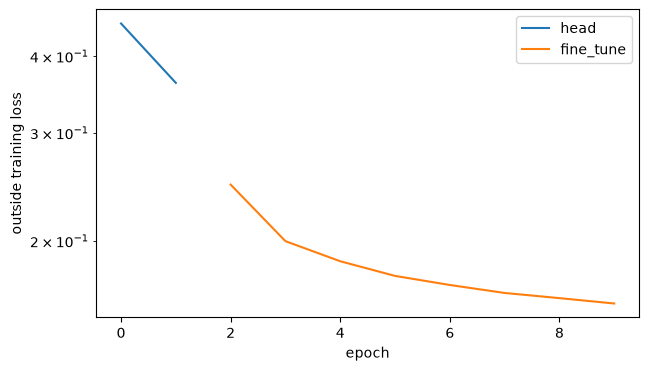

In [9]:
STAGE1_DIR = RUN_DIR / "stage1_outside_pretraining"
STAGE1_DIR.mkdir()
stage1_deploy, stage1_model, stage1_backbone = build_models()


def stage_callbacks(directory, stage, early_stop=True):
    callbacks = [
        keras.callbacks.CSVLogger(str(directory / f"{stage}_history.csv")),
        keras.callbacks.TerminateOnNaN(),
    ]
    if early_stop:
        callbacks[:0] = [
            keras.callbacks.ModelCheckpoint(str(directory / f"{stage}_best.weights.h5"), monitor="val_loss",
                                            save_best_only=True, save_weights_only=True, verbose=1),
            keras.callbacks.EarlyStopping(monitor="val_loss", patience=EARLY_STOP_PATIENCE, verbose=1),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3,
                                              patience=max(1, EARLY_STOP_PATIENCE // 2), min_lr=1e-6, verbose=1),
        ]
    return callbacks


pretrain_steps = (PRETRAIN_STEPS_PER_EPOCH if PRETRAIN_STEPS_PER_EPOCH is not None
                  else math.ceil(len(outside_records) / BATCH_SIZE))
stage1_started = time.perf_counter()
stage1_histories = {}
if WEIGHTS is not None and PRETRAIN_HEAD_EPOCHS > 0:
    stage1_backbone.trainable = False
    stage1_model.compile(optimizer=keras.optimizers.Adam(PRETRAIN_HEAD_LR), loss=detector_loss)
    stage1_histories["head"] = stage1_model.fit(
        pretrain_ds, steps_per_epoch=pretrain_steps, epochs=PRETRAIN_HEAD_EPOCHS,
        callbacks=stage_callbacks(STAGE1_DIR, "head", early_stop=False))

if PRETRAIN_EPOCHS > 0:
    stage1_backbone.trainable = True
    stage1_model.compile(optimizer=keras.optimizers.Adam(PRETRAIN_LR), loss=detector_loss)
    stage1_histories["fine_tune"] = stage1_model.fit(
        pretrain_ds, steps_per_epoch=pretrain_steps, epochs=PRETRAIN_EPOCHS,
        callbacks=stage_callbacks(STAGE1_DIR, "fine_tune", early_stop=False))

STAGE1_WEIGHTS = STAGE1_DIR / "stage1_complete.weights.h5"
stage1_model.save_weights(STAGE1_WEIGHTS)
STAGE1_MINUTES = (time.perf_counter() - stage1_started) / 60
print(f"Stage 1 completed in {STAGE1_MINUTES:.1f} min; weights: {STAGE1_WEIGHTS}")

fig, ax = plt.subplots(figsize=(7, 4))
offset = 0
for stage, history in stage1_histories.items():
    n = len(history.history["loss"])
    ax.plot(range(offset, offset + n), history.history["loss"], label=stage)
    offset += n
ax.set(xlabel="epoch", ylabel="outside training loss", yscale="log")
ax.legend()
plt.savefig(STAGE1_DIR / "training_loss.png", dpi=140, bbox_inches="tight")
del stage1_deploy, stage1_model, stage1_backbone
keras.backend.clear_session()


## 10. Stage 2: paired ESP32-only and outside-pretrained arms



Training arm: esp32_only
Epoch 1/6
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 848ms/step - loss: 0.6037
Epoch 1: val_loss improved from None to 1.99721, saving model to /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/Multi_Object_Detector/runs/esp32_roi_detector_v3_128_20261110T052149Z/esp32_only/head_best.weights.h5

Epoch 1: finished saving model to /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/Multi_Object_Detector/runs/esp32_roi_detector_v3_128_20261110T052149Z/esp32_only/head_best.weights.h5
500/500 ━━━━━━━━━━━━━━━━━━━━ 432s 857ms/step - loss: 0.6037 - val_loss: 1.9972 - learning_rate: 0.0020
Epoch 2/6
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 815ms/step - loss: 0.4343
Epoch 2: val_loss did not improve from 1.99721
500/500 ━━━━━━━━━━━━━━━━━━━━ 408s 817ms/step - loss: 0.4343 - val_loss: 2.4451 - learning_rate: 0.0020
Epoch 3/6
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 811ms/step - loss: 0.4016
Epoch 3: val_loss improved from 1.99721 to 1.66007, saving model to /mnt/c/Users/Joe/

/home/joe/venvs/ESPclassifier/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 887ms/step - loss: 0.4979
Epoch 1: val_loss improved from None to 1.52726, saving model to /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/Multi_Object_Detector/runs/esp32_roi_detector_v3_128_20261110T052149Z/outside_pretrained/head_best.weights.h5

Epoch 1: finished saving model to /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/Multi_Object_Detector/runs/esp32_roi_detector_v3_128_20261110T052149Z/outside_pretrained/head_best.weights.h5
500/500 ━━━━━━━━━━━━━━━━━━━━ 449s 892ms/step - loss: 0.4979 - val_loss: 1.5273 - learning_rate: 0.0020
Epoch 2/6
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 865ms/step - loss: 0.4223
Epoch 2: val_loss did not improve from 1.52726
500/500 ━━━━━━━━━━━━━━━━━━━━ 433s 867ms/step - loss: 0.4223 - val_loss: 1.5727 - learning_rate: 0.0020
Epoch 3/6
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 894ms/step - loss: 0.4052
Epoch 3: val_loss did not improve from 1.52726
500/500 ━━━━━━━━━━━━━━━━━━━━ 448s 895ms/step - loss: 0.405

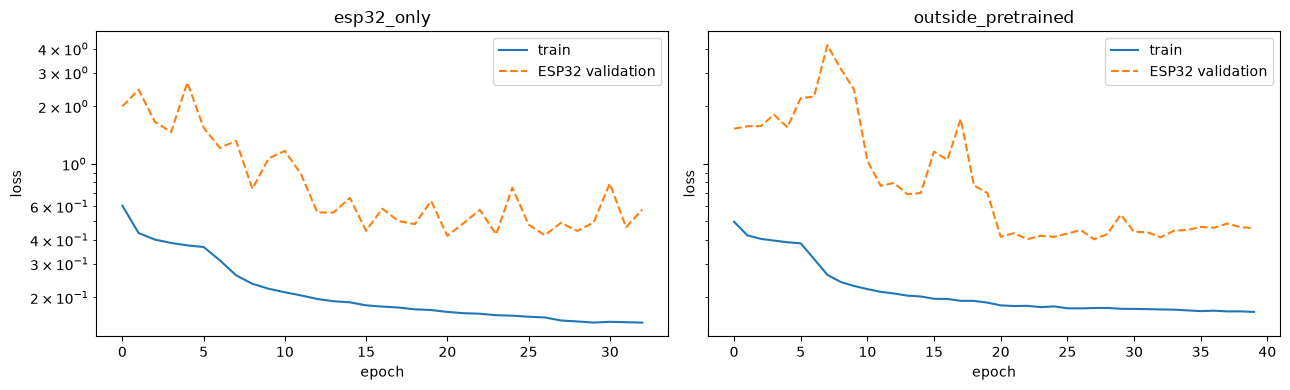

In [10]:
ARM_CONFIGS = {
    "esp32_only": {"dataset": control_ds, "initial_weights": None, "head_warmup": True},
    "outside_pretrained": {"dataset": transfer_ds, "initial_weights": STAGE1_WEIGHTS, "head_warmup": True},
}


def train_arm(name, config):
    arm_dir = RUN_DIR / name
    arm_dir.mkdir()
    keras.utils.set_random_seed(SEED + 500)  # identical fresh head initialization where applicable
    deploy, model, backbone = build_models()
    if config["initial_weights"] is not None:
        model.load_weights(str(config["initial_weights"]))
    histories = {}
    started = time.perf_counter()
    if config["head_warmup"] and WEIGHTS is not None and HEAD_EPOCHS > 0:
        backbone.trainable = False
        model.compile(optimizer=keras.optimizers.Adam(HEAD_LR), loss=detector_loss)
        histories["head"] = model.fit(
            config["dataset"], steps_per_epoch=STEPS_PER_EPOCH, epochs=HEAD_EPOCHS,
            validation_data=val_ds, callbacks=stage_callbacks(arm_dir, "head", early_stop=True))
        model.load_weights(str(arm_dir / "head_best.weights.h5"))
    if FINE_TUNE_EPOCHS > 0:
        backbone.trainable = True
        model.compile(optimizer=keras.optimizers.Adam(FINE_TUNE_LR), loss=detector_loss)
        histories["fine_tune"] = model.fit(
            config["dataset"], steps_per_epoch=STEPS_PER_EPOCH, epochs=FINE_TUNE_EPOCHS,
            validation_data=val_ds, callbacks=stage_callbacks(arm_dir, "fine_tune", early_stop=True))
    best = {stage: min(history.history["val_loss"]) for stage, history in histories.items()}
    best_stage = min(best, key=best.get)
    model.load_weights(str(arm_dir / f"{best_stage}_best.weights.h5"))
    model.save_weights(arm_dir / "selected_float.weights.h5")
    deploy.save(arm_dir / "esp32_detector.keras")
    minutes = (time.perf_counter() - started) / 60
    history_rows = []
    offset = 0
    for stage, history in histories.items():
        for epoch in range(len(history.history["loss"])):
            history_rows.append({"stage": stage, "global_epoch": offset + epoch,
                                 **{key: values[epoch] for key, values in history.history.items()}})
        offset += len(history.history["loss"])
    pd.DataFrame(history_rows).to_csv(arm_dir / "combined_history.csv", index=False)
    return {"name": name, "dir": arm_dir, "deploy": deploy, "model": model, "backbone": backbone,
            "histories": histories, "best_stage": best_stage, "best_val_loss": best[best_stage], "minutes": minutes}


arms = {}
for arm_name, arm_config in ARM_CONFIGS.items():
    print("\nTraining arm:", arm_name)
    arms[arm_name] = train_arm(arm_name, arm_config)
    print(arm_name, "best stage", arms[arm_name]["best_stage"], "val loss", arms[arm_name]["best_val_loss"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (arm_name, arm) in zip(axes, arms.items()):
    frame = pd.read_csv(arm["dir"] / "combined_history.csv")
    ax.plot(frame["global_epoch"], frame["loss"], label="train")
    ax.plot(frame["global_epoch"], frame["val_loss"], "--", label="ESP32 validation")
    ax.set(title=arm_name, xlabel="epoch", ylabel="loss", yscale="log")
    ax.legend()
plt.tight_layout()
plt.savefig(RUN_DIR / "stage2_training_comparison.png", dpi=140, bbox_inches="tight")


## 11. Export both arms to full-integer TFLite


In [14]:
def representative_dataset():
    rng = np.random.default_rng(SEED + 77)
    for _ in range(REPRESENTATIVE_SAMPLES):
        # Calibration is deployment-domain data and is identical for both arms.
        draw = draw_esp32(rng)
        record = draw["record"]
        image = load_roi_tensor(record["path"], roi_to_crop_box(draw["roi"], record["width"], record["height"]),
                                tf.constant(draw["flip"]))
        yield [image[None]]


def export_arm(arm):
    deploy = arm["deploy"]
    arm_dir = arm["dir"]
    float_path = arm_dir / "esp32_detector_float32.tflite"
    int8_path = arm_dir / "esp32_detector_int8.tflite"
    float_path.write_bytes(tf.lite.TFLiteConverter.from_keras_model(deploy).convert())
    converter = tf.lite.TFLiteConverter.from_keras_model(deploy)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.representative_dataset = representative_dataset
    converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    converter.inference_input_type = tf.uint8
    converter.inference_output_type = tf.int8
    int8_path.write_bytes(converter.convert())
    interpreter = tf.lite.Interpreter(model_path=str(int8_path), experimental_op_resolver_type=tf.lite.experimental.OpResolverType.BUILTIN_WITHOUT_DEFAULT_DELEGATES,)
    interpreter.allocate_tensors()
    ops = sorted({item["op_name"] for item in interpreter._get_ops_details()})
    unsupported = set(ops) - {"ADD", "CONV_2D", "DEPTHWISE_CONV_2D", "MUL", "QUANTIZE"}
    if unsupported:
        raise RuntimeError(f"Unexpected TFLite ops for {arm['name']}: {sorted(unsupported)}")
    arm.update({"float_path": float_path, "int8_path": int8_path, "tflite_ops": ops})
    print(arm["name"], float_path.stat().st_size, "float bytes;", int8_path.stat().st_size, "int8 bytes", ops)


for arm in arms.values():
    export_arm(arm)


INFO:tensorflow:Assets written to: /tmp/tmp372ldr9v/assets


INFO:tensorflow:Assets written to: /tmp/tmp372ldr9v/assets


Saved artifact at '/tmp/tmp372ldr9v'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='image')
Output Type:
  List[TensorSpec(shape=(None, 8, 8, 12), dtype=tf.float32, name=None), TensorSpec(shape=(None, 8, 8, 3), dtype=tf.float32, name=None)]
Captures:
  123830687588688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123829253420432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123829253422352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123829253419472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123829253422544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123829253421776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123829253419856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123829253422736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123829253420048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12382925340699

W0000 00:00:1794352817.468760    1556 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1794352817.468812    1556 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1794352817.468982    1556 reader.cc:83] Reading SavedModel from: /tmp/tmp372ldr9v
I0000 00:00:1794352817.474880    1556 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1794352817.474909    1556 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp372ldr9v
I0000 00:00:1794352817.528318    1556 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1794352817.865344    1556 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmp372ldr9v
I0000 00:00:1794352817.945377    1556 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 476408 microseconds.


INFO:tensorflow:Assets written to: /tmp/tmp7ug3h5fu/assets


INFO:tensorflow:Assets written to: /tmp/tmp7ug3h5fu/assets


... (8 outputs left out)

Saved artifact at '/tmp/tmp9jpw3s2f'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='image')
Output Type:
  List[TensorSpec(shape=(None, 8, 8, 12), dtype=tf.float32, name=None), TensorSpec(shape=(None, 8, 8, 3), dtype=tf.float32, name=None)]
Captures:
  123828080493008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123828080498960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123828080493200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123828080498768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123828080499920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123828080499344: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123828080498384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123828080500112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123828080500304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12382808050126

/home/joe/venvs/ESPclassifier/lib/python3.12/site-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1794352844.272397    1556 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1794352844.272445    1556 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1794352844.272587    1556 reader.cc:83] Reading SavedModel from: /tmp/tmp9jpw3s2f
I0000 00:00:1794352844.277975    1556 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1794352844.278004    1556 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp9jpw3s2f
I0000 00:00:1794352844.340243    1556 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1794352844.675820    1556 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmp9jpw3s2f
I0000 00:00:1794352844.761139    1556 loader.cc:471] SavedModel load for ta

outside_pretrained 460632 float bytes; 248528 int8 bytes ['ADD', 'CONV_2D', 'DEPTHWISE_CONV_2D', 'MUL', 'QUANTIZE']


fully_quantize: 0, inference_type: 6, input_inference_type: UINT8, output_inference_type: INT8
W0000 00:00:1794352855.572898    1556 flatbuffer_export.cc:3851] Skipping runtime version metadata in the model. This will be generated by the exporter.
/home/joe/venvs/ESPclassifier/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


## 12. Decode and run the paired int8 evaluation


/home/joe/venvs/ESPclassifier/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


esp32_only threshold 0.16 {'input': [[1.0, 0.0], 'uint8'], 'box': [[0.01732902228832245, -22.0], 'int8', 'StatefulPartitionedCall_1:0'], 'score': [[0.058158569037914276, 57.0], 'int8', 'StatefulPartitionedCall_1:1'], 'host_ms_per_roi': 0.5300468971297896}


/home/joe/venvs/ESPclassifier/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/home/joe/venvs/ESPclassifier/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


outside_pretrained threshold 0.26 {'input': [[1.0, 0.0], 'uint8'], 'box': [[0.017150184139609337, -9.0], 'int8', 'StatefulPartitionedCall_1:0'], 'score': [[0.04980005696415901, 44.0], 'int8', 'StatefulPartitionedCall_1:1'], 'host_ms_per_roi': 0.4598437866362539}


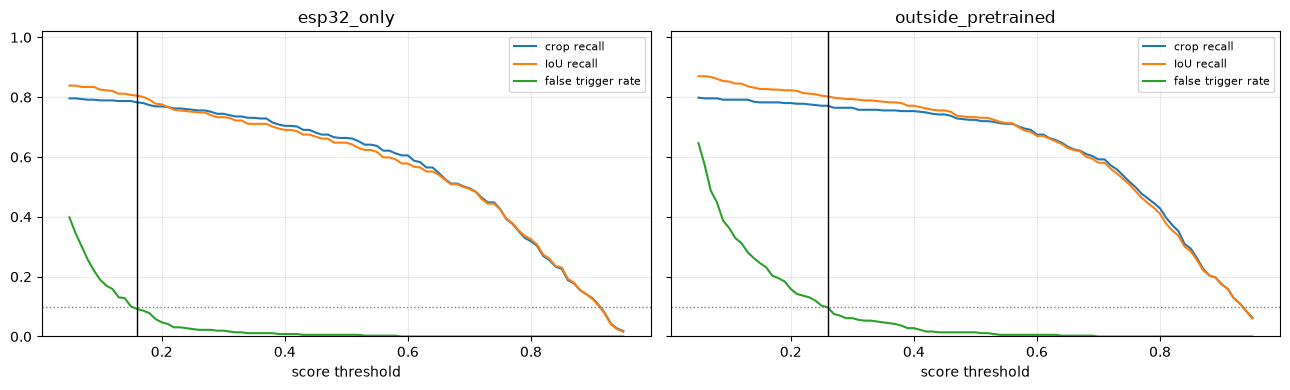

In [15]:
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))


GY, GX = np.meshgrid(np.arange(GRID), np.arange(GRID), indexing="ij")


def decode(box_raw, score_raw, threshold=CANDIDATE_SCORE_THRESHOLD):
    """Raw float outputs (G, G, A*4) and (G, G, A) -> boxes (N, 4) normalized xyxy, scores (N,)."""
    b = box_raw.reshape(GRID, GRID, NUM_ANCHORS, 4)
    s = sigmoid(score_raw.reshape(GRID, GRID, NUM_ANCHORS))
    cx = (sigmoid(b[..., 0]) * 3 - 1 + GX[..., None]) / GRID
    cy = (sigmoid(b[..., 1]) * 3 - 1 + GY[..., None]) / GRID
    w = ANCHORS[:, 0] * np.exp(np.clip(b[..., 2], -4, 4))
    h = ANCHORS[:, 1] * np.exp(np.clip(b[..., 3], -4, 4))
    boxes = np.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], -1).reshape(-1, 4)
    scores = s.reshape(-1)
    keep = scores >= threshold
    boxes, scores = np.clip(boxes[keep], 0, 1), scores[keep]
    order = np.argsort(-scores)
    chosen = []
    while order.size and len(chosen) < MAX_DETECTIONS:
        i = order[0]
        chosen.append(i)
        order = order[1:][iou_one_to_many(boxes[i], boxes[order[1:]]) < NMS_IOU]
    return boxes[chosen], scores[chosen]


def iou_one_to_many(box, boxes):
    if len(boxes) == 0:
        return np.zeros(0)
    ix = np.clip(np.minimum(box[2], boxes[:, 2]) - np.maximum(box[0], boxes[:, 0]), 0, None)
    iy = np.clip(np.minimum(box[3], boxes[:, 3]) - np.maximum(box[1], boxes[:, 1]), 0, None)
    inter = ix * iy
    area = lambda bb: (bb[..., 2] - bb[..., 0]) * (bb[..., 3] - bb[..., 1])
    return inter / np.maximum(area(box) + area(boxes) - inter, 1e-9)


def crop_coverage(det_norm, gt_norm):
    """Share of each GT box inside the context-expanded crop of det (ROI-normalized coords)."""
    w, h = det_norm[2] - det_norm[0], det_norm[3] - det_norm[1]
    crop = np.array([det_norm[0] - PI_CROP_CONTEXT * w, det_norm[1] - PI_CROP_CONTEXT * h,
                     det_norm[2] + PI_CROP_CONTEXT * w, det_norm[3] + PI_CROP_CONTEXT * h])
    ix = np.clip(np.minimum(crop[2], gt_norm[:, 2]) - np.maximum(crop[0], gt_norm[:, 0]), 0, None)
    iy = np.clip(np.minimum(crop[3], gt_norm[:, 3]) - np.maximum(crop[1], gt_norm[:, 1]), 0, None)
    return ix * iy / np.maximum((gt_norm[:, 2] - gt_norm[:, 0]) * (gt_norm[:, 3] - gt_norm[:, 1]), 1e-9)


def limit(items):
    if TFLITE_EVAL_LIMIT is None or len(items) <= TFLITE_EVAL_LIMIT:
        return items
    rng = np.random.default_rng(SEED + 5)
    return [items[i] for i in sorted(rng.choice(len(items), TFLITE_EVAL_LIMIT, replace=False))]


def roi_image(item):
    r = item["record"]
    return load_roi_tensor(r["path"], roi_to_crop_box(item["roi"], r["width"], r["height"]), tf.constant(False)).numpy()


def run_tflite(model_path, items):
    interpreter = tf.lite.Interpreter(model_path=str(model_path), num_threads=4)
    interpreter.allocate_tensors()
    inp = interpreter.get_input_details()[0]
    outs = {d["name"]: d for d in interpreter.get_output_details()}
    # Identify box/score outputs by channel count, never by order.
    box_d = next(d for d in outs.values() if d["shape"][-1] == NUM_ANCHORS * 4)
    score_d = next(d for d in outs.values() if d["shape"][-1] == NUM_ANCHORS)

    def deq(detail):
        raw = interpreter.get_tensor(detail["index"])[0]
        scale, zero = detail["quantization"]
        return raw.astype(np.float32) if scale == 0 else (raw.astype(np.float32) - zero) * scale

    results, seconds = [], 0.0
    for item in items:
        x = roi_image(item)[None]
        if inp["dtype"] == np.uint8:
            scale, zero = inp["quantization"]
            x = np.clip(np.rint(x / scale + zero), 0, 255).astype(np.uint8)
        interpreter.set_tensor(inp["index"], x.astype(inp["dtype"]))
        t0 = time.perf_counter()
        interpreter.invoke()
        seconds += time.perf_counter() - t0
        results.append((deq(box_d), deq(score_d)))
    details = {"input": [list(map(float, inp["quantization"])), np.dtype(inp["dtype"]).name],
               "box": [list(map(float, box_d["quantization"])), np.dtype(box_d["dtype"]).name, box_d["name"]],
               "score": [list(map(float, score_d["quantization"])), np.dtype(score_d["dtype"]).name, score_d["name"]],
               "host_ms_per_roi": 1000 * seconds / max(1, len(items))}
    return results, details


def roi_outcomes(items, raw_outputs):
    """Per ROI: best detection score for crop recall / IoU recall, and max score for false triggers."""
    rows = []
    for item, (box_raw, score_raw) in zip(items, raw_outputs):
        boxes, scores = decode(box_raw, score_raw)
        gt = item["positives"]
        row = {"sample_id": item["record"]["sample_id"], "split_group": item["record"]["group"],
               "mode": item["mode"], "source": item["record"]["source"],
               "sensor": item["record"]["sensor"], "camera_id": item["record"]["camera_id"],
               "species": "|".join(item["record"]["species"]), "has_bird": len(gt) > 0,
               "negative": len(gt) == 0 and len(item["ignores"]) == 0,
               "max_score": float(scores.max()) if len(scores) else 0.0,
               "crop_hit_score": 0.0, "iou_hit_score": 0.0}
        if len(gt) and len(boxes):
            # The firmware sends one crop: the top detection. Score it as such.
            top = boxes[0]
            if (crop_coverage(top, gt) >= CROP_COVERAGE_MIN).any():
                row["crop_hit_score"] = float(scores[0])
            ious = np.array([iou_one_to_many(b, gt).max() for b in boxes])
            hits = scores[ious >= IOU_MATCH]
            row["iou_hit_score"] = float(hits.max()) if len(hits) else 0.0
        rows.append(row)
    return pd.DataFrame(rows)


def metrics_at(outcomes, threshold):
    birds, negatives = outcomes[outcomes["has_bird"]], outcomes[outcomes["negative"]]
    return {
        "threshold": float(threshold),
        "bird_rois": len(birds), "negative_rois": len(negatives),
        "crop_recall": float((birds["crop_hit_score"] >= threshold).mean()) if len(birds) else np.nan,
        "iou_recall": float((birds["iou_hit_score"] >= threshold).mean()) if len(birds) else np.nan,
        "false_trigger_rate": float((negatives["max_score"] >= threshold).mean()) if len(negatives) else np.nan,
    }


def select_threshold(outcomes):
    thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)
    tuned = outcomes[outcomes["mode"].isin(THRESHOLD_MODES)]
    sweep = pd.DataFrame([metrics_at(tuned, threshold) for threshold in thresholds])
    valid = sweep[sweep["false_trigger_rate"] <= MAX_FALSE_TRIGGER_RATE]
    if valid.empty:
        return float(thresholds[-1]), sweep
    chosen = valid.sort_values(["crop_recall", "threshold"], ascending=[False, False]).iloc[0]
    return float(chosen["threshold"]), sweep


val_eval = limit(val_rois)
test_eval = limit(test_rois)
for arm in arms.values():
    val_raw, val_details = run_tflite(arm["int8_path"], val_eval)
    arm["val_outcomes"] = roi_outcomes(val_eval, val_raw)
    arm["threshold"], arm["sweep"] = select_threshold(arm["val_outcomes"])
    arm["sweep"].to_csv(arm["dir"] / "validation_threshold_sweep_int8.csv", index=False)
    test_raw, test_details = run_tflite(arm["int8_path"], test_eval)
    arm["test_outcomes"] = roi_outcomes(test_eval, test_raw)
    arm["val_outcomes"].to_csv(arm["dir"] / "validation_roi_outcomes.csv", index=False)
    arm["test_outcomes"].to_csv(arm["dir"] / "test_roi_outcomes.csv", index=False)
    arm["tensor_details"] = {"validation": val_details, "test": test_details}
    print(arm["name"], "threshold", arm["threshold"], val_details)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, arm in zip(axes, arms.values()):
    sweep = arm["sweep"]
    ax.plot(sweep["threshold"], sweep["crop_recall"], label="crop recall")
    ax.plot(sweep["threshold"], sweep["iou_recall"], label="IoU recall")
    ax.plot(sweep["threshold"], sweep["false_trigger_rate"], label="false trigger rate")
    ax.axhline(MAX_FALSE_TRIGGER_RATE, color="grey", lw=1, ls=":")
    ax.axvline(arm["threshold"], color="black", lw=1)
    ax.set(title=arm["name"], xlabel="score threshold", ylim=(0, 1.02))
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(RUN_DIR / "validation_threshold_comparison.png", dpi=140, bbox_inches="tight")


## 13. Same-split comparison by mode, sensor source, and species


In [16]:
def result_slices(arm_name, split, outcomes, threshold):
    rows = []

    def add(slice_type, slice_name, part):
        rows.append({"arm": arm_name, "split": split, "slice_type": slice_type, "slice": slice_name,
                     **metrics_at(part, threshold)})

    motion = outcomes[outcomes["mode"].isin(THRESHOLD_MODES)]
    add("headline", "motion_rois", motion)
    add("headline", "all", outcomes)
    for mode, part in outcomes.groupby("mode", dropna=False):
        add("mode", str(mode), part)
    for source, part in motion.groupby("source", dropna=False):
        add("source", str(source), part)
    for (mode, source), part in outcomes.groupby(["mode", "source"], dropna=False):
        add("mode_source", f"{mode} / {source}", part)
    bird = motion[motion["has_bird"]].copy()
    bird["species"] = bird["species"].replace("", "unlabelled")
    for species, part in bird.groupby("species"):
        add("species", str(species), part)
    return rows


comparison_rows = []
for arm_name, arm in arms.items():
    comparison_rows += result_slices(arm_name, "validation", arm["val_outcomes"], arm["threshold"])
    comparison_rows += result_slices(arm_name, "test", arm["test_outcomes"], arm["threshold"])
comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(RUN_DIR / "comparison_by_mode_source_species.csv", index=False)
display(comparison[(comparison["slice_type"].isin(["headline", "mode", "source"]))])

# Join paired ROI outcomes and expose hit indicators at each arm's frozen threshold.
paired = None
for arm_name, arm in arms.items():
    frame = arm["test_outcomes"].copy()
    frame[f"{arm_name}_crop_hit"] = frame["crop_hit_score"] >= arm["threshold"]
    frame[f"{arm_name}_iou_hit"] = frame["iou_hit_score"] >= arm["threshold"]
    frame[f"{arm_name}_trigger"] = frame["max_score"] >= arm["threshold"]
    keep = ["sample_id", "split_group", "mode", "source", "sensor", "camera_id", "species", "has_bird", "negative",
            f"{arm_name}_crop_hit", f"{arm_name}_iou_hit", f"{arm_name}_trigger"]
    paired = frame[keep] if paired is None else paired.merge(frame[keep], on=[
        "sample_id", "split_group", "mode", "source", "sensor", "camera_id", "species", "has_bird", "negative"],
        validate="one_to_one")
paired.to_csv(RUN_DIR / "paired_test_roi_results.csv", index=False)

control_name, transfer_name = "esp32_only", "outside_pretrained"
control_hit = f"{control_name}_crop_hit"
transfer_hit = f"{transfer_name}_crop_hit"
paired_birds = paired[paired["has_bird"] & paired["mode"].isin(THRESHOLD_MODES)].copy()


def session_bootstrap_delta(frame, replicates=BOOTSTRAP_REPLICATES):
    grouped = frame.groupby("split_group")[[control_hit, transfer_hit]].mean()
    if not len(grouped):
        return {"delta": np.nan, "ci_low": np.nan, "ci_high": np.nan, "sessions": 0, "bird_rois": 0}
    values = grouped[[control_hit, transfer_hit]].to_numpy(np.float64)
    rng = np.random.default_rng(SEED + 909)
    deltas = np.empty(replicates, np.float64)
    for index in range(replicates):
        sample = values[rng.integers(0, len(values), len(values))]
        deltas[index] = sample[:, 1].mean() - sample[:, 0].mean()
    return {"delta": float(values[:, 1].mean() - values[:, 0].mean()),
            "ci_low": float(np.quantile(deltas, 0.025)), "ci_high": float(np.quantile(deltas, 0.975)),
            "sessions": len(grouped), "bird_rois": len(frame)}


bootstrap_rows = [{"slice_type": "headline", "slice": "motion_rois", **session_bootstrap_delta(paired_birds)}]
for mode, part in paired_birds.groupby("mode"):
    bootstrap_rows.append({"slice_type": "mode", "slice": mode, **session_bootstrap_delta(part)})
for source, part in paired_birds.groupby("source"):
    bootstrap_rows.append({"slice_type": "source", "slice": source, **session_bootstrap_delta(part)})
for species, part in paired_birds.groupby(paired_birds["species"].replace("", "unlabelled")):
    bootstrap_rows.append({"slice_type": "species", "slice": species, **session_bootstrap_delta(part)})
bootstrap = pd.DataFrame(bootstrap_rows)
bootstrap.to_csv(RUN_DIR / "paired_session_bootstrap.csv", index=False)
display(bootstrap)

# Rare-visitor table: training frequency is image-level and test recall remains explicitly denominator-aware.
train_species = Counter(species for record in train_records for species in record["species"])
rare_rows = []
species_results = comparison[(comparison["split"].eq("test")) & comparison["slice_type"].eq("species")]
for row in species_results.itertuples(index=False):
    rare_rows.append({"arm": row.arm, "species": row.slice, "train_images": train_species.get(row.slice, 0),
                      "test_bird_rois": row.bird_rois, "crop_recall": row.crop_recall})
rare = pd.DataFrame(rare_rows).sort_values(["train_images", "species", "arm"])
rare.to_csv(RUN_DIR / "rare_visitor_results.csv", index=False)
display(rare)


,arm,split,slice_type,slice,threshold,bird_rois,negative_rois,crop_recall,iou_recall,false_trigger_rate
0,esp32_only,validation,headline,motion_rois,0.16,446,359,0.782511,0.804933,0.091922
1,esp32_only,validation,headline,all,0.16,756,545,0.697090,0.702381,0.231193
2,esp32_only,validation,mode,bird_roi,0.16,330,0,0.836364,0.866667,NaN
3,esp32_only,validation,mode,random_roi,0.16,116,359,0.629310,0.629310,0.091922
4,esp32_only,validation,mode,whole_frame,0.16,310,186,0.574194,0.554839,0.500000
5,esp32_only,validation,source,OV2640,0.16,278,154,0.791367,0.816547,0.071429
6,esp32_only,validation,source,OV5640,0.16,168,205,0.767857,0.785714,0.107317
20,esp32_only,test,headline,motion_rois,0.16,589,365,0.811545,0.831919,0.076712
21,esp32_only,test,headline,all,0.16,996,489,0.650602,0.688755,0.196319
22,esp32_only,test,mode,bird_roi,0.16,431,0,0.904872,0.921114,NaN


,slice_type,slice,delta,ci_low,ci_high,sessions,bird_rois
0,headline,motion_rois,-0.016834,-0.038069,-0.002433,6,589
1,mode,bird_roi,-0.016011,-0.038438,0.005000,6,431
2,mode,random_roi,-0.021755,-0.088964,0.047348,4,158
3,source,OV2640,-0.027778,-0.083333,0.000000,4,72
4,source,OV5640,-0.021643,-0.042550,-0.005000,4,517
5,species,Black-capped Chickadee,0.000000,0.000000,0.000000,2,18
6,species,Black-capped Chickadee|House Sparrow,-0.070192,-0.125000,-0.015385,2,73
7,species,House Sparrow,-0.015980,-0.041787,0.000000,5,492
8,species,White-breasted Nuthatch,-0.166667,-0.166667,-0.166667,1,6


,arm,species,train_images,test_bird_rois,crop_recall
1,esp32_only,Black-capped Chickadee|House Sparrow,0,73,0.808219
5,outside_pretrained,Black-capped Chickadee|House Sparrow,0,73,0.780822
3,esp32_only,White-breasted Nuthatch,17,6,1.000000
7,outside_pretrained,White-breasted Nuthatch,17,6,0.833333
0,esp32_only,Black-capped Chickadee,52,18,0.833333
4,outside_pretrained,Black-capped Chickadee,52,18,0.833333
2,esp32_only,House Sparrow,924,492,0.808943
6,outside_pretrained,House Sparrow,924,492,0.770325


## 14. Keep outside data only if it wins, then emit the selected firmware artifacts


In [17]:
headline = comparison[(comparison["split"].eq("test")) & comparison["slice_type"].eq("headline")
                      & comparison["slice"].eq("motion_rois")].set_index("arm")
control_metrics = headline.loc["esp32_only"].to_dict()
transfer_metrics = headline.loc["outside_pretrained"].to_dict()
outside_wins = bool(
    transfer_metrics["false_trigger_rate"] <= MAX_FALSE_TRIGGER_RATE
    and transfer_metrics["crop_recall"] > control_metrics["crop_recall"]
)
SELECTED_ARM = "outside_pretrained" if outside_wins else "esp32_only"
selected = arms[SELECTED_ARM]
decision = {
    "selected_arm": SELECTED_ARM,
    "outside_data_kept": outside_wins,
    "rule": "outside_pretrained test motion-ROI crop recall must exceed ESP32-only while false-trigger rate <= 0.10",
    "esp32_only": control_metrics,
    "outside_pretrained": transfer_metrics,
    "paired_session_bootstrap": bootstrap.iloc[0].to_dict(),
}
(RUN_DIR / "winner_decision.json").write_text(json.dumps(json_safe(decision), indent=2), encoding="utf-8")
print(json.dumps(json_safe(decision), indent=2))

SELECTED_DIR = RUN_DIR / "selected_model"
SELECTED_DIR.mkdir()
for source in (selected["float_path"], selected["int8_path"], selected["dir"] / "esp32_detector.keras",
               selected["dir"] / "selected_float.weights.h5"):
    shutil.copy2(source, SELECTED_DIR / source.name)

INT8_PATH = SELECTED_DIR / "esp32_detector_int8.tflite"
int8_bytes = INT8_PATH.read_bytes()
interpreter = tf.lite.Interpreter(model_path=str(INT8_PATH))
interpreter.allocate_tensors()
inp = interpreter.get_input_details()[0]
output_details = interpreter.get_output_details()
box_d = next(d for d in output_details if d["shape"][-1] == NUM_ANCHORS * 4)
score_d = next(d for d in output_details if d["shape"][-1] == NUM_ANCHORS)
box_q, score_q = box_d["quantization"], score_d["quantization"]
DEPLOY_THRESHOLD = selected["threshold"]
TFLITE_OPS = selected["tflite_ops"]

contract = {
    "schema_version": 2,
    "run_name": RUN_NAME,
    "experiment": "ESP32-only v2.1 control versus outside pretraining plus 75/25 sampler-level fine-tuning",
    "selected_arm": SELECTED_ARM,
    "model_file": INT8_PATH.name,
    "model_sha256": hashlib.sha256(int8_bytes).hexdigest(),
    "model_bytes": len(int8_bytes),
    "model_macs": MODEL_MACS,
    "tflite_ops": TFLITE_OPS,
    "input": {"shape": inp["shape"].tolist(), "dtype": np.dtype(inp["dtype"]).name,
              "color_order": "RGB", "quantization": list(map(float, inp["quantization"])),
              "numeric_scaling": "[0,255] -> [-1,1] inside the model"},
    "anchors_normalized_wh": ANCHORS.tolist(),
    "decode": {"center_x": "(sigmoid(tx) * 3 - 1 + gx) / G",
               "center_y": "(sigmoid(ty) * 3 - 1 + gy) / G",
               "width": "anchor_w * exp(clamp(tw, -4, 4))", "height": "anchor_h * exp(clamp(th, -4, 4))",
               "score": "sigmoid(logit)", "candidate_score_threshold": CANDIDATE_SCORE_THRESHOLD,
               "nms_iou": NMS_IOU, "max_detections": MAX_DETECTIONS,
               "deployment_score_threshold": DEPLOY_THRESHOLD,
               "deployment_logit_threshold": float(np.log(DEPLOY_THRESHOLD / (1 - DEPLOY_THRESHOLD)))},
    "roi": {"function": "square_roi", "expand": ROI_EXPAND,
            "min_side_fraction_of_min_frame_dim": ROI_MIN_SIDE_FRACTION},
    "pi_crop": {"detection": "top-scoring box only", "context_per_edge": PI_CROP_CONTEXT,
                "output": [PI_CROP_SIZE, PI_CROP_SIZE, 3], "pad_value": PAD_VALUE},
    "threshold_policy": {"modes": list(THRESHOLD_MODES), "max_false_trigger_rate": MAX_FALSE_TRIGGER_RATE},
    "validation_int8": metrics_at(selected["val_outcomes"][selected["val_outcomes"]["mode"].isin(THRESHOLD_MODES)],
                                  DEPLOY_THRESHOLD),
    "test_int8": metrics_at(selected["test_outcomes"][selected["test_outcomes"]["mode"].isin(THRESHOLD_MODES)],
                            DEPLOY_THRESHOLD),
    "training": {"seed": SEED, "quick_run": QUICK_RUN, "stage1_minutes": STAGE1_MINUTES,
                 "stage2_minutes": {name: arm["minutes"] for name, arm in arms.items()},
                 "sample_mix": SAMPLE_MIX, "transfer_esp32_share": TRANSFER_ESP32_SHARE,
                 "outside_images": len(outside_records), "inat_min_score": INAT_MIN_SCORE},
    "data_audit": audit,
    "winner_decision": decision,
}
(SELECTED_DIR / "esp32_detector_contract.json").write_text(json.dumps(json_safe(contract), indent=2), encoding="utf-8")

hex_lines = [", ".join(f"0x{value:02x}" for value in int8_bytes[index:index + 16])
             for index in range(0, len(int8_bytes), 16)]
(SELECTED_DIR / "esp32_detector_model.h").write_text(
    "// Generated by train_esp32_roi_detector_v3.ipynb - do not edit.\n"
    f"// {RUN_NAME} / {SELECTED_ARM} / sha256 {contract['model_sha256']}\n"
    "#pragma once\n#include <stddef.h>\n#include <stdint.h>\n\n"
    "alignas(16) const uint8_t kBirdDetectorModel[] = {\n  " + ",\n  ".join(hex_lines) + "\n};\n"
    f"const size_t kBirdDetectorModelLen = {len(int8_bytes)};\n", encoding="utf-8")

anchor_rows = ",\n  ".join(f"{{{anchor[0]:.6f}f, {anchor[1]:.6f}f}}" for anchor in ANCHORS)
(SELECTED_DIR / "esp32_detector_contract.h").write_text(f"""// Generated by train_esp32_roi_detector_v3.ipynb - do not edit.
// {RUN_NAME} / {SELECTED_ARM}
#pragma once

constexpr int kDetInputSize = {INPUT_SIZE};
constexpr int kDetGrid = {GRID};
constexpr int kDetAnchors = {NUM_ANCHORS};
constexpr float kDetAnchorsWH[kDetAnchors][2] = {{
  {anchor_rows}
}};
constexpr float kDetBoxScale = {box_q[0]:.9g}f;
constexpr int kDetBoxZeroPoint = {int(box_q[1])};
constexpr float kDetScoreScale = {score_q[0]:.9g}f;
constexpr int kDetScoreZeroPoint = {int(score_q[1])};
constexpr float kDetScoreThreshold = {DEPLOY_THRESHOLD:.4f}f;
constexpr float kDetCandidateThreshold = {CANDIDATE_SCORE_THRESHOLD:.4f}f;
constexpr float kDetNmsIou = {NMS_IOU:.3f}f;
constexpr int kDetMaxDetections = {MAX_DETECTIONS};
constexpr int kDetOpCount = {len(TFLITE_OPS)};
constexpr float kRoiExpand = {ROI_EXPAND:.4f}f;
constexpr float kRoiMinSideFraction = {ROI_MIN_SIDE_FRACTION:.4f}f;
constexpr int kPadValue = {PAD_VALUE};
constexpr float kPiCropContext = {PI_CROP_CONTEXT:.4f}f;
constexpr int kPiCropSize = {PI_CROP_SIZE};
""", encoding="utf-8")

print("Selected", SELECTED_ARM, "and wrote deployment artifacts to", SELECTED_DIR)
for path in sorted(SELECTED_DIR.iterdir()):
    print(f"  {path.name:42s} {path.stat().st_size / 1024:9.1f} KiB")


{
  "selected_arm": "esp32_only",
  "outside_data_kept": false,
  "rule": "outside_pretrained test motion-ROI crop recall must exceed ESP32-only while false-trigger rate <= 0.10",
  "esp32_only": {
    "split": "test",
    "slice_type": "headline",
    "slice": "motion_rois",
    "threshold": 0.16,
    "bird_rois": 589,
    "negative_rois": 365,
    "crop_recall": 0.8115449915110357,
    "iou_recall": 0.831918505942275,
    "false_trigger_rate": 0.07671232876712329
  },
  "outside_pretrained": {
    "split": "test",
    "slice_type": "headline",
    "slice": "motion_rois",
    "threshold": 0.26,
    "bird_rois": 589,
    "negative_rois": 365,
    "crop_recall": 0.7741935483870968,
    "iou_recall": 0.8387096774193549,
    "false_trigger_rate": 0.09863013698630137
  },
  "paired_session_bootstrap": {
    "slice_type": "headline",
    "slice": "motion_rois",
    "delta": -0.016834131690997567,
    "ci_low": -0.038069305048661684,
    "ci_high": -0.0024330900243307862,
    "sessions": 6,


/home/joe/venvs/ESPclassifier/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


## 15. Interpretation checklist

After the full run:

1. Read `winner_decision.json` first. It applies the requested keep/drop rule to outside data.
2. Check `comparison_by_mode_source_species.csv` for regressions hidden by the headline metric.
3. Check `paired_session_bootstrap.csv`; session-level confidence intervals are more honest than treating burst frames as independent.
4. Inspect `rare_visitor_results.csv`, but retain the denominators: very rare species can have unstable recall estimates.
5. Deploy only the files in `selected_model/`. Both arm directories remain for audit and reproduction.
